In [ ]:
import sys
from pathlib import Path
import os
os.environ['OMP_NUM_THREADS'] = '1'   #HGBR runs ~15x faster single-threaded on our small data (macOS threading overhead)
import numpy as np
import pandas as pd
import statsmodels.api as sm
import joblib

pd.set_option('display.max_columns', None)

#find the project root
ROOT=Path.cwd()
while not (ROOT / ".git").exists() and ROOT!=ROOT.parent:
    ROOT=ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

OUT = ROOT / 'misc'
OUT.mkdir(parents=True, exist_ok=True)   #creates misc/ if it doesn't exist
(OUT / 'misc' / 'joblib').mkdir(parents=True, exist_ok=True)

from config import START_YEAR, END_YEAR, HOLDOUT_START, MP_THRESHOLD, MIN_GAMES_SHARE, MIN_MP
import utils

df_tot=utils.player_stat_dataframe(START_YEAR, END_YEAR)
df_tot.shape

RUN_TUNING = False     #set to False after the first run, so run-all skips the search (results are saved to csv)

In [14]:
df_holdout=df_tot[df_tot['Year'] >= HOLDOUT_START].copy() #locked away until the very end
df_tot=df_tot[df_tot['Year'] < HOLDOUT_START].copy() #everything below uses only this
print(df_tot['Year'].max(), "last development season") #should be 2018

2018 last development season


In [15]:
df_tot.head()

,Year,W%,Code,Player,Age,Team,Pos,G,GS,GS%,...,TRB,AST,STL,BLK,TOV,PF,PTS,AS,MVP,MVPVS
0,1980,0.756098,ervinju01,Julius Erving,30.0,PHI,SF,82.0,82.0,0.976190,...,8.0,4.4,2.1,1.8,3.2,2.8,24.6,1,1,0.658
1,1980,0.756098,birdla01,Larry Bird,24.0,BOS,PF,82.0,82.0,0.976190,...,10.9,5.5,2.0,0.8,3.5,2.9,21.2,1,0,0.613
2,1980,0.658537,abdulka01,Kareem Abdul-Jabbar,33.0,LAL,C,80.0,80.0,0.952381,...,10.3,3.4,0.7,2.9,3.1,3.1,26.2,1,0,0.414
3,1980,0.487805,malonmo01,Moses Malone,25.0,HOU,C,80.0,80.0,0.952381,...,14.8,1.8,1.0,1.9,3.9,2.8,27.8,1,0,0.261
4,1980,0.634146,gervige01,George Gervin,28.0,SAS,SG,82.0,82.0,0.976190,...,5.1,3.2,1.1,0.7,3.1,2.6,27.1,1,0,0.120


In [16]:
#traded players: utils already keeps only the 2TM/3TM season-total row; this flag and filter are a safety net in case that changes
is_total=df_tot['Team'].str.endswith('TM')
df_tot['TradedMidSeason']=is_total.groupby([df_tot['Year'], df_tot['Code']]).transform('any').astype(int)

#season length = most games any single-team player played that season (50 in 1998-99, 66 in 2011-12, ...)
season_games=df_tot[~is_total].groupby('Year')['G'].max()
df_tot['SeasonG']=df_tot['Year'].map(season_games)
df_tot['GP%']=df_tot['G'] / df_tot['SeasonG']      #recomputed: the loader divides by the most games in the file, which a traded player's total can exceed

#keep one row per player-season: single-team players keep their row, traded players only keep their total row
season_rows=df_tot[(df_tot['TradedMidSeason']== 0) | is_total]

#MVP eligibility, step 1 of the two-step model:the CBA rule since 2023-24 is 65 games with 20+ minutes.
#This is applied to EVERY season, scaled to season length(40 of 50 games in 1998-99, 53 of 66 in 2011-12..)because voters already kinda behaved this way (see the check in the next cell).
#Our data only has season averages, so 20+ mins == MP >=20 per game, and the rule's injury exceptions aren't modeled.-->could keep 60+ games if we want to account fir injuries etc
min_games=np.ceil(MIN_GAMES_SHARE * season_rows['SeasonG'])
eligible=(season_rows['G'] >= min_games) & (season_rows['MP'] >= MIN_MP)

data=season_rows[eligible].reset_index(drop=True)

print(data.shape)
print(data.duplicated(['Year', 'Code']).sum(), "duplicate player-seasons")
print((data['MVPVS'] > 0).sum(), "vote-getter rows")
print(data.groupby('Year')['MVP'].sum().eq(1).all(), "every season still has its MVP")

assert (data['MVP'] == (data['MVPVS'] == data.groupby('Year')['MVPVS'].transform('max'))).all(), 'MVP flag does not match the top vote share'

(6287, 39)
0 duplicate player-seasons
610 vote-getter rows
True every season still has its MVP


In [17]:
#check: which vote-getters does the rule remove, and did any of them finish top 3?
removed=season_rows[~eligible & (season_rows['MVPVS'] > 0)]
vote_rank=season_rows.groupby('Year')['MVPVS'].rank(ascending=False, method='min')
share=removed['MVPVS'].sum() / season_rows['MVPVS'].sum() * 100
print(len(removed), f'vote-getters removed, with {share:.1f}% of all vote share')
print((vote_rank[removed.index] <= 3).sum(), 'of them finished top 3')
removed.sort_values('MVPVS', ascending=False)[['Year', 'Player', 'G', 'SeasonG', 'MP', 'MVPVS']].head(10)

39 vote-getters removed, with 0.8% of all vote share
0 of them finished top 3


,Year,Player,G,SeasonG,MP,MVPVS
6138,1997,Shaquille O'Neal,60.0,82.0,36.3,0.268
1252,1984,Bernard King,55.0,82.0,37.5,0.090
5273,1995,Shaquille O'Neal,54.0,82.0,36.0,0.056
15803,2018,Joel Embiid,64.0,82.0,33.7,0.049
13327,2013,Chris Paul,62.0,82.0,35.0,0.036
7900,2001,Chris Webber,54.0,82.0,38.4,0.029
3301,1990,Larry Bird,60.0,82.0,38.0,0.026
10,1980,Magic Johnson,37.0,82.0,37.1,0.026
7902,2001,Allen Iverson,60.0,82.0,43.7,0.023
315,1981,Dan Roundfield,61.0,82.0,36.3,0.020


In [18]:
#now feature lists and within-season z-scores.
feature_sets = {
    'heatmap_8':        ['PTS', 'W%', 'FT', 'eFG%', 'TRB', 'AST', 'BLK', 'STL'],
    'candidates_10':    ['PTS', 'W%', 'FT', 'eFG%', 'DRB', 'AST', 'BLK', 'STL', 'GS', '3P'],
    'rf_recall_6':      ['PTS', 'W%', 'DRB', 'AST', 'BLK', 'STL'],
}
#rf_recall_6: best feature set for the Random Forest classifier (classifier.ipynb), chosen on development seasons only
all_feats=sorted(set().union(*feature_sets.values()))

#within-season z-score for each feature: (value - season mean) / season std, then check no NaNs
for col in all_feats:
    g=data.groupby('Year')[col]
    data[col + '_z']=(data[col] - g.transform('mean'))/g.transform('std')

print(data[[c + '_z' for c in all_feats]].isna().sum())

3P_z      0
AST_z     0
BLK_z     0
DRB_z     0
FT_z      0
GS_z      0
PTS_z     0
STL_z     0
TRB_z     0
W%_z      0
eFG%_z    0
dtype: int64


### Quasi-binomial regression for MVP vote share

For each player-season, the model computes a linear score from the within-season z-scored features, then converts it to a predicted vote share between 0 and 1:
$$\text{score} = b_0 + b_1\,\text{PTS}_z + b_2\,\text{W\%}_z + \dots + b_k\,\text{STL}_z$$

$$\text{vote share} = \frac{1}{1 + e^{-\text{score}}}$$

- $b_0$ is the intercept: the score of a player at the season average in every feature.
- Each $b_i$ shows how much one standard deviation in that feature changes the score; $e^{b_i}$ is the multiplier on the odds.
- `scale='X2'` makes it quasi-binomial: the coefficients are the same as a binomial fit, but the dispersion is estimated from the data, so the standard errors and p-values are realistic.

In [19]:
fits={}
for name, feats in feature_sets.items():
    zf=[c + '_z' for c in feats]
    X=sm.add_constant(data[zf])
    fits[name]=sm.GLM(data['MVPVS'], X, family=sm.families.Binomial()).fit(scale='X2')  #quasi-binomial
    print(f"\n===== {name} (dispersion {fits[name].scale:.4f})")
    print(fits[name].summary())


===== heatmap_8 (dispersion 0.0278)
                 Generalized Linear Model Regression Results                  
Dep. Variable:                  MVPVS   No. Observations:                 6287
Model:                            GLM   Df Residuals:                     6278
Model Family:                Binomial   Df Model:                            8
Link Function:                  Logit   Scale:                        0.027767
Method:                          IRLS   Log-Likelihood:                -148.06
Date:                Mon, 16 Nov 2026   Deviance:                       106.22
Time:                        17:38:52   Pearson chi2:                     174.
No. Iterations:                    13   Pseudo R-squ. (CS):            0.09879
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -

In [20]:
def evaluate(df, score_col):
    hits, ranks=0, []
    for yr,g in df.groupby('Year'):
        assert g['MVP'].sum() == 1, f"{yr}: expected exactly one MVP, found {g['MVP'].sum()}"
        actual=g.loc[g['MVP'].idxmax(), 'Code']
        order=g.sort_values(score_col, ascending=False)['Code'].tolist()
        hits+=order[0] == actual #True gets 1
        ranks.append(order.index(actual) +1) #so top position is 1 and not 0
    print(f"{score_col}: picked MVP in {hits}/{len(ranks)} seasons,", f"real winner's avg rank={np.mean(ranks):.2f}")


In [21]:
import warnings
warnings.filterwarnings('ignore')   #hides repeated warnings from the fits

MIN_HISTORY=10 #seasons of training data before any predictions
years=sorted(data['Year'].unique())
test_years=years[MIN_HISTORY:] #1990 onward

for name, feats in feature_sets.items():
    zf=[c + '_z' for c in feats]
    col=f'pred_{name}'
    data[col]=np.nan

    for yr in test_years:
        train=data['Year'] < yr #only seasons before the test season
        test=data['Year'] == yr
        assert data.loc[train, 'Year'].max() < yr
        model=sm.GLM(data.loc[train, 'MVPVS'], sm.add_constant(data.loc[train, zf]),
                     family=sm.families.Binomial()).fit(scale='X2')
        data.loc[test, col]=model.predict(sm.add_constant(data.loc[test, zf], has_constant='add'))

tested=data[data['Year'].isin(test_years)]    #runs once, after all fits
for name in feature_sets:
    evaluate(tested, f'pred_{name}')
evaluate(tested, 'PTS')    #baseline, once

pred_heatmap_8: picked MVP in 18/29 seasons, real winner's avg rank=1.93
pred_candidates_10: picked MVP in 17/29 seasons, real winner's avg rank=1.90
pred_rf_recall_6: picked MVP in 17/29 seasons, real winner's avg rank=2.00
PTS: picked MVP in 10/29 seasons, real winner's avg rank=5.21


## Hyperparameter tuning

In [ ]:
#hyperparameter tuning for gradient boosting (only the version in the comparison: raw candidates_10)
#each setting is scored like the models: forward-chaining over 1990-2018, then MVP hits (top 3 and avg rank break ties).
#Tuning on these seasons makes gradient boosting's dev numbers slightly optimistic; the 2019-2025 hold-out is the honest test.
from threadpoolctl import threadpool_limits
from sklearn.model_selection import ParameterSampler
from sklearn.ensemble import HistGradientBoostingRegressor


tune_feats = feature_sets['candidates_10']

def forward_score(params, years):
    """Forward-chain HGBR with these settings; return (hits, top 3, average rank of the real MVP)."""
    ranks = []
    for yr in years:
        train, test = data['Year'] < yr, data['Year'] == yr
        model = HistGradientBoostingRegressor(random_state=12, **params)
        model.fit(data.loc[train, tune_feats], data.loc[train, 'MVPVS'])
        g = data.loc[test].assign(score=model.predict(data.loc[test, tune_feats]))
        order = g.sort_values('score', ascending=False)['Code'].tolist()
        ranks.append(order.index(g.loc[g['MVP'] == 1, 'Code'].iloc[0]) + 1)
    ranks = np.array(ranks)
    return (ranks == 1).sum(), (ranks <= 3).sum(), ranks.mean()

param_dist = {
    'loss': ('squared_error', 'poisson'),
    'learning_rate': (0.01, 0.03, 0.05, 0.08),
    'max_iter': (100, 200, 300, 400),
    'max_depth': (2, 3, 4, 6, None),
    'max_leaf_nodes': (7, 15, 31),
    'min_samples_leaf': (5, 10, 15, 25),
    'l2_regularization': (0.0, 0.1, 1.0, 5.0),
}

if RUN_TUNING:
    param_list = [{}] + list(ParameterSampler(param_dist, n_iter=25, random_state=12))   #{} = defaults, for comparison
    rows = []
    with threadpool_limits(limits=1):          #1 thread is ~15x faster on this small data (see timing check)
        for params in param_list:
            hits, top3, avg_rank = forward_score(params, test_years)
            rows.append({**params, 'hits': hits, 'top3': top3, 'avg_rank': round(avg_rank, 2)})
    tuning = pd.DataFrame(rows).sort_values(['hits', 'top3', 'avg_rank'], ascending=[False, False, True])
    tuning.to_csv( OUT / 'gbr_tuning.csv', index=False)
    display(tuning.head(10))

Looking at HGBR using the sklearn CV functions

In [177]:
feature_sets['candidates_10']

['PTS', 'W%', 'FT', 'eFG%', 'DRB', 'AST', 'BLK', 'STL', 'GS', '3P']

In [201]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

tune_feats = feature_sets['candidates_10']
target = 'MVPVS'

train = data[data['Year'] < HOLDOUT_START]

X_tr, y_tr = train[tune_feats], train[target]


cv = list(utils.forward_chaining_splits(train.Year, min_train_years=10))


search = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=29),
    param_distributions = {
    'loss': ('squared_error', 'poisson'),
    'learning_rate': (0.01, 0.03, 0.05),
    'max_iter': (100, 200),
    'max_depth': (2, 3, 4, None),
    'max_leaf_nodes': (7, 15, 31),
    'min_samples_leaf': (1,2,3,4,5),
    'l2_regularization': (0.0, 0.5, 1.0),
 },
    n_iter=200,
    cv=cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    random_state=29,
)
search.fit(X_tr, y_tr)
joblib.dump(search.best_estimator_, str(ROOT/'misc/joblib/tuned_hgbr_model.joblib'), compress=3)

['/home/fss4/workspace/fss4/erdos/basketball/fall-2026-nba-mvp-prediction/misc/joblib/tuned_hgbr_model.joblib']

In [190]:
pd.DataFrame(search.cv_results_).sort_values('rank_test_score').head(3)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_min_samples_leaf,param_max_leaf_nodes,param_max_iter,param_max_depth,param_loss,param_learning_rate,param_l2_regularization,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,split5_test_score,split6_test_score,split7_test_score,split8_test_score,split9_test_score,split10_test_score,split11_test_score,split12_test_score,split13_test_score,split14_test_score,split15_test_score,split16_test_score,split17_test_score,split18_test_score,split19_test_score,split20_test_score,split21_test_score,split22_test_score,split23_test_score,split24_test_score,split25_test_score,split26_test_score,split27_test_score,split28_test_score,mean_test_score,std_test_score,rank_test_score
25,0.042445,0.003197,0.002090,0.000097,1,7,200,None,squared_error,0.03,0.5,"{'min_samples_leaf': 1, 'max_leaf_nodes': 7, '...",-0.001225,-0.001750,-0.002192,-0.003174,-0.001085,-0.001476,-0.000689,-0.001009,-0.004293,-0.001689,-0.003494,-0.004531,-0.004864,-0.001654,-0.010959,-0.003763,-0.000861,-0.005276,-0.001131,-0.000867,-0.002422,-0.003104,-0.001443,-0.002802,-0.002120,-0.001928,-0.004698,-0.003494,-0.002344,-0.002770,0.002038,1
184,0.039828,0.002956,0.002070,0.000067,1,7,200,4,squared_error,0.05,0.0,"{'min_samples_leaf': 1, 'max_leaf_nodes': 7, '...",-0.001190,-0.001736,-0.002256,-0.003045,-0.001046,-0.001255,-0.000734,-0.000891,-0.004521,-0.001667,-0.003289,-0.004550,-0.005004,-0.001079,-0.010625,-0.004166,-0.000717,-0.005577,-0.000976,-0.000754,-0.002317,-0.003618,-0.001517,-0.002437,-0.001914,-0.002620,-0.005188,-0.003626,-0.002371,-0.002782,0.002081,2
75,0.042619,0.002505,0.002084,0.000116,1,7,200,None,squared_error,0.05,1.0,"{'min_samples_leaf': 1, 'max_leaf_nodes': 7, '...",-0.001276,-0.001749,-0.002403,-0.003265,-0.000883,-0.001755,-0.000685,-0.001031,-0.004897,-0.001471,-0.003322,-0.004550,-0.004913,-0.001217,-0.011332,-0.003996,-0.000739,-0.005088,-0.000798,-0.000636,-0.002703,-0.003471,-0.001224,-0.002240,-0.001522,-0.001995,-0.004841,-0.004226,-0.002475,-0.002783,0.002172,3


In [191]:
tmp_data = data.copy()
tmp_data['HGBR_pred'] = [0.0]*len(tmp_data)
model = search.best_estimator_
result = pd.DataFrame(columns=['Year','MVPVS','HGBR_pred','ActualWinner','PredictedWinner','Top3','Match'])
for chain in cv:
    model.fit(X_tr.iloc[chain[0]],y_tr.iloc[chain[0]])
    y_pred = model.predict(X_tr.iloc[chain[1]])
    tmp_data.loc[chain[1],'HGBR_pred'] = y_pred
    true_mvp = tmp_data.iloc[chain[1]].sort_values('MVPVS', ascending=False).iloc[0]
    pred_mvp = tmp_data.iloc[chain[1]].sort_values('HGBR_pred', ascending=False).iloc[0]
    top3 = list(tmp_data.iloc[chain[1]].sort_values('HGBR_pred', ascending=False).iloc[0:3].Player)
    tmp = pd.DataFrame({'Year': [int(true_mvp['Year'])], 
                   'MVPVS': [float(true_mvp['MVPVS'])], 
                   'HGBR_pred': [float(pred_mvp['HGBR_pred'])], 
                   'ActualWinner': [str(true_mvp['Player'])], 
                   'PredictedWinner': [str(pred_mvp['Player'])],
                   'Top3': [str(true_mvp['Player']) in top3],
                   'Match':[ (str(pred_mvp['Player']) == str(true_mvp['Player']))]}
                    )
    result = pd.concat([result,tmp],ignore_index=True)
    
tmp_data[(tmp_data.Year >= 1990)][['Player','MVPVS','HGBR_pred']]
print(f'{result.Match.sum()}/{len(result)}')
result

22/29


,Year,MVPVS,HGBR_pred,ActualWinner,PredictedWinner,Top3,Match
0,1990,0.928,0.831473,Michael Jordan,Michael Jordan,True,True
1,1991,0.938,0.763611,Michael Jordan,Michael Jordan,True,True
2,1992,0.852,1.012714,Charles Barkley,Charles Barkley,True,True
3,1993,0.88,0.384665,Hakeem Olajuwon,Hakeem Olajuwon,True,True
4,1994,0.858,0.759047,David Robinson,David Robinson,True,True
5,1995,0.986,0.77316,Michael Jordan,Michael Jordan,True,True
6,1996,0.857,0.801126,Karl Malone,Michael Jordan,True,False
7,1997,0.934,0.855756,Michael Jordan,Michael Jordan,True,True
8,1998,0.701,0.486685,Karl Malone,Karl Malone,True,True
9,1999,0.998,0.828729,Shaquille O'Neal,Shaquille O'Neal,True,True


### AdaBoostRegressor

In [192]:
from scipy.stats import randint, loguniform
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import RandomizedSearchCV

tune_feats = feature_sets['candidates_10']
target = 'MVPVS'

train = data[data['Year'] < HOLDOUT_START]

X_tr, y_tr = train[tune_feats], train[target]

ada = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(),  # use base_estimator= on sklearn < 1.2
    random_state=42,
)

param_distributions = {
    # AdaBoost's own params
    "n_estimators": randint(50, 1000),
    "learning_rate": loguniform(1e-3, 1.0),
    "loss": ["linear", "square", "exponential"],

    # Params of the base tree (note the estimator__ prefix)
    "estimator__max_depth": randint(1, 10),
    "estimator__min_samples_split": randint(2, 20),
    "estimator__min_samples_leaf": randint(1, 20),
    "estimator__max_features": [None, "sqrt", "log2"],
}

search = RandomizedSearchCV(
    ada,
    param_distributions=param_distributions,
    n_iter=50,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

search.fit(X_tr, y_tr)
print(search.best_params_)
print(-search.best_score_)  # RMSE
joblib.dump(search.best_estimator_, str(ROOT/'misc/joblib/tuned_ada_model.joblib'), compress=3)

Fitting 29 folds for each of 50 candidates, totalling 1450 fits
{'estimator__max_depth': 9, 'estimator__max_features': None, 'estimator__min_samples_leaf': 9, 'estimator__min_samples_split': 4, 'learning_rate': np.float64(0.0010491954332267905), 'loss': 'exponential', 'n_estimators': 698}
0.051323136378501034


['/home/fss4/workspace/fss4/erdos/basketball/fall-2026-nba-mvp-prediction/misc/joblib/tuned_ada_model.joblib']

In [193]:
pd.DataFrame(search.cv_results_).sort_values('rank_test_score').head(3)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_estimator__max_depth,param_estimator__max_features,param_estimator__min_samples_leaf,param_estimator__min_samples_split,param_learning_rate,param_loss,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,split5_test_score,split6_test_score,split7_test_score,split8_test_score,split9_test_score,split10_test_score,split11_test_score,split12_test_score,split13_test_score,split14_test_score,split15_test_score,split16_test_score,split17_test_score,split18_test_score,split19_test_score,split20_test_score,split21_test_score,split22_test_score,split23_test_score,split24_test_score,split25_test_score,split26_test_score,split27_test_score,split28_test_score,mean_test_score,std_test_score,rank_test_score
21,7.567345,2.670153,0.043722,0.007404,9,NaN,9,4,0.001049,exponential,698,"{'estimator__max_depth': 9, 'estimator__max_fe...",-0.037723,-0.039346,-0.040034,-0.055054,-0.025792,-0.039727,-0.028012,-0.033172,-0.079781,-0.035868,-0.049524,-0.070057,-0.067754,-0.055449,-0.107657,-0.074381,-0.027948,-0.078419,-0.042442,-0.029834,-0.042014,-0.057340,-0.033976,-0.054672,-0.041489,-0.046814,-0.086971,-0.055888,-0.051233,-0.051323,0.019642,1
48,3.930042,1.315620,0.024486,0.003980,7,NaN,4,14,0.003827,square,449,"{'estimator__max_depth': 7, 'estimator__max_fe...",-0.033633,-0.038649,-0.039237,-0.055792,-0.025924,-0.038650,-0.031873,-0.034197,-0.078831,-0.037462,-0.058251,-0.067969,-0.063241,-0.054639,-0.107037,-0.075604,-0.020886,-0.099866,-0.043344,-0.033832,-0.039633,-0.056352,-0.035991,-0.051712,-0.042515,-0.044060,-0.085537,-0.057224,-0.050090,-0.051794,0.020859,2
44,4.100109,1.377041,0.038598,0.003072,7,NaN,3,19,0.046817,exponential,615,"{'estimator__max_depth': 7, 'estimator__max_fe...",-0.047296,-0.048031,-0.044375,-0.049463,-0.053573,-0.053345,-0.034738,-0.028950,-0.078782,-0.033583,-0.052831,-0.066087,-0.065670,-0.047544,-0.103461,-0.072571,-0.013459,-0.090501,-0.040304,-0.026073,-0.045896,-0.051909,-0.043008,-0.043661,-0.051976,-0.046096,-0.075203,-0.052222,-0.046669,-0.051975,0.018603,3


In [197]:
tmp_data = data.copy()
tmp_data['Ada_pred'] = [0.0]*len(tmp_data)
model = search.best_estimator_
result = pd.DataFrame(columns=['Year','MVPVS','Ada_pred','ActualWinner','PredictedWinner','Top3','Match'])
for chain in cv:
    model.fit(X_tr.iloc[chain[0]],y_tr.iloc[chain[0]])
    y_pred = model.predict(X_tr.iloc[chain[1]])
    tmp_data.loc[chain[1],'Ada_pred'] = y_pred
    true_mvp = tmp_data.iloc[chain[1]].sort_values('MVPVS', ascending=False).iloc[0]
    pred_mvp = tmp_data.iloc[chain[1]].sort_values('Ada_pred', ascending=False).iloc[0]
    top3 = list(tmp_data.iloc[chain[1]].sort_values('Ada_pred', ascending=False).iloc[0:3].Player)
    tmp = pd.DataFrame({'Year': [int(true_mvp['Year'])], 
                   'MVPVS': [float(true_mvp['MVPVS'])], 
                   'Ada_pred': [float(pred_mvp['Ada_pred'])], 
                   'ActualWinner': [str(true_mvp['Player'])], 
                   'PredictedWinner': [str(pred_mvp['Player'])],
                   'Top3': [str(true_mvp['Player']) in top3],
                   'Match':[ (str(pred_mvp['Player']) == str(true_mvp['Player']))]}
                    )
    result = pd.concat([result,tmp],ignore_index=True)
    

print(f'{result.Match.sum()}/{len(result)}')
result

22/29


,Year,MVPVS,Ada_pred,ActualWinner,PredictedWinner,Top3,Match
0,1990,0.928,0.698143,Michael Jordan,Michael Jordan,True,True
1,1991,0.938,0.761222,Michael Jordan,Michael Jordan,True,True
2,1992,0.852,0.795182,Charles Barkley,Charles Barkley,True,True
3,1993,0.88,0.4,Hakeem Olajuwon,David Robinson,True,False
4,1994,0.858,0.869875,David Robinson,David Robinson,True,True
5,1995,0.986,0.8835,Michael Jordan,Michael Jordan,True,True
6,1996,0.857,0.8994,Karl Malone,Michael Jordan,True,False
7,1997,0.934,0.875917,Michael Jordan,Michael Jordan,True,True
8,1998,0.701,0.2496,Karl Malone,Shaquille O'Neal,True,False
9,1999,0.998,0.872769,Shaquille O'Neal,Shaquille O'Neal,True,True


### GradientBoostRegressor

In [203]:
from scipy.stats import randint, uniform, loguniform
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

tune_feats = feature_sets['candidates_10']
target = 'MVPVS'

train = data[data['Year'] < HOLDOUT_START]

X_tr, y_tr = train[tune_feats], train[target]

gbr = GradientBoostingRegressor(random_state=42)

param_distributions = {
    # Boosting params
    "n_estimators": randint(100, 1000),
    "learning_rate": loguniform(1e-3, 0.3),
    "subsample": uniform(0.5, 0.5),          # samples from 0.5 to 1.0
    "loss": ["squared_error", "absolute_error", "huber"],

    # Tree params
    "max_depth": randint(2, 8),
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(1, 20),
    "max_features": [None, "sqrt", "log2"],
}

search = RandomizedSearchCV(
    gbr,
    param_distributions=param_distributions,
    n_iter=50,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

search.fit(X_tr, y_tr)
print(search.best_params_)
print(-search.best_score_)  # RMSE

joblib.dump(search.best_estimator_, str(ROOT/'misc/joblib/tuned_gbr_model.joblib'), compress=3)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
{'learning_rate': np.float64(0.01847809198229244), 'loss': 'squared_error', 'max_depth': 5, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 9, 'n_estimators': 611, 'subsample': np.float64(0.6983919136069442)}
0.05380576935832321


['/home/fss4/workspace/fss4/erdos/basketball/fall-2026-nba-mvp-prediction/misc/joblib/tuned_gbr_model.joblib']

In [204]:
pd.DataFrame(search.cv_results_).sort_values('rank_test_score').head(3)

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_learning_rate,param_loss,param_max_depth,param_max_features,param_min_samples_leaf,param_min_samples_split,param_n_estimators,param_subsample,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
42,3.457620,0.062330,0.004772,0.000870,0.018478,squared_error,5,NaN,1,9,611,0.698392,"{'learning_rate': 0.01847809198229244, 'loss':...",-0.052405,-0.047570,-0.067465,-0.051244,-0.050345,-0.053806,0.007014,1
25,1.125410,0.023430,0.005923,0.000271,0.018150,squared_error,4,log2,4,4,610,0.613248,"{'learning_rate': 0.018149722592157965, 'loss'...",-0.053855,-0.046755,-0.066855,-0.054666,-0.048372,-0.054101,0.007068,2
11,0.532197,0.008476,0.003114,0.000148,0.081382,squared_error,3,log2,9,8,300,0.811649,"{'learning_rate': 0.08138233922650512, 'loss':...",-0.054143,-0.048048,-0.067059,-0.053241,-0.050146,-0.054527,0.006634,3


In [206]:
tmp_data = data.copy()
tmp_data['GBR_pred'] = [0.0]*len(tmp_data)
model = search.best_estimator_
result = pd.DataFrame(columns=['Year','MVPVS','GBR_pred','ActualWinner','PredictedWinner','Top3','Match'])
for chain in cv:
    model.fit(X_tr.iloc[chain[0]],y_tr.iloc[chain[0]])
    y_pred = model.predict(X_tr.iloc[chain[1]])
    tmp_data.loc[chain[1],'GBR_pred'] = y_pred
    true_mvp = tmp_data.iloc[chain[1]].sort_values('MVPVS', ascending=False).iloc[0]
    pred_mvp = tmp_data.iloc[chain[1]].sort_values('GBR_pred', ascending=False).iloc[0]
    top3 = list(tmp_data.iloc[chain[1]].sort_values('GBR_pred', ascending=False).iloc[0:3].Player)
    tmp = pd.DataFrame({'Year': [int(true_mvp['Year'])], 
                   'MVPVS': [float(true_mvp['MVPVS'])], 
                   'GBR_pred': [float(pred_mvp['GBR_pred'])], 
                   'ActualWinner': [str(true_mvp['Player'])], 
                   'PredictedWinner': [str(pred_mvp['Player'])],
                   'Top3': [str(true_mvp['Player']) in top3],
                   'Match':[ (str(pred_mvp['Player']) == str(true_mvp['Player']))]}
                    )
    result = pd.concat([result,tmp],ignore_index=True)
    

print(f'{result.Match.sum()}/{len(result)}')
result

20/29


,Year,MVPVS,GBR_pred,ActualWinner,PredictedWinner,Top3,Match
0,1990,0.928,0.818031,Michael Jordan,Michael Jordan,True,True
1,1991,0.938,0.939033,Michael Jordan,Michael Jordan,True,True
2,1992,0.852,0.835959,Charles Barkley,Charles Barkley,True,True
3,1993,0.88,0.470737,Hakeem Olajuwon,Hakeem Olajuwon,True,True
4,1994,0.858,0.853126,David Robinson,David Robinson,True,True
5,1995,0.986,0.810933,Michael Jordan,Michael Jordan,True,True
6,1996,0.857,0.86215,Karl Malone,Michael Jordan,True,False
7,1997,0.934,0.818314,Michael Jordan,Karl Malone,True,False
8,1998,0.701,0.387593,Karl Malone,Karl Malone,True,True
9,1999,0.998,0.889297,Shaquille O'Neal,Shaquille O'Neal,True,True


In [23]:
# #timing check (run once): 4 seasons took 5.9 s with all CPU threads vs 0.4 s with 1 thread,
# #which is why OMP_NUM_THREADS=1 is set in cell 0. Uncomment to rerun.
# import time
# from threadpoolctl import threadpool_limits    #comes with scikit-learn

# for n in [None, 1]:                             #None = no limit (the default)
#     t = time.time()
#     with threadpool_limits(limits=n):
#         forward_score({}, range(2015, 2019))
#     print('threads:', n or 'all', '->', round(time.time() - t, 1), 's for 4 seasons')

**Tuning result:** 25 random settings were scored with forward-chaining on 1990–2018 (see `misc/gbr_tuning.csv`). The best (learning_rate 0.03, max_iter 200, max_leaf_nodes 15, min_samples_leaf 5, l2_regularization 1.0) picked 23/29 MVPs vs 22/29 for the defaults, so we use it (`BEST_GBR`). The gain is one season, measured on the same seasons used to choose it, so treat it as small; on 2001–2018 both settings pick 12/18.

In [24]:
#best setting from the tuning search (23/29 vs 22/29 for defaults on 1990-2018)
#BEST_GBR = {'learning_rate': 0.03, 'max_iter': 200, 'max_leaf_nodes': 15,
#             'min_samples_leaf': 5, 'l2_regularization': 1.0, 'loss': 'squared_error'}

#best HGBR settings, read from the tuning results so they update automatically whenever the search is rerun
tuning = pd.read_csv( OUT / 'gbr_tuning.csv')
tuning = tuning.sort_values(['hits', 'top3', 'avg_rank'], ascending=[False, False, True])   #same ranking as the search

best = tuning.iloc[0].drop(['hits', 'top3', 'avg_rank']).dropna()   #top row; NaN = setting left at its default
INT_PARAMS = ['max_iter', 'max_leaf_nodes', 'min_samples_leaf', 'max_depth']   #the csv stores these as decimals
BEST_GBR = {k: (int(v) if k in INT_PARAMS else v) for k, v in best.items()}
print(BEST_GBR)

{'min_samples_leaf': 5, 'max_leaf_nodes': 15, 'max_iter': 200, 'loss': 'squared_error', 'learning_rate': np.float64(0.03), 'l2_regularization': np.float64(1.0)}


In [25]:
for name, feats in feature_sets.items():
    for kind, cols in [('raw', feats), ('z', [c + '_z' for c in feats])]:
        col=f'gbr_{kind}_{name}'
        data[col]=np.nan
        for yr in test_years:
            train=data['Year'] < yr
            test=data['Year'] == yr
            assert data.loc[train, 'Year'].max() < yr
            model=HistGradientBoostingRegressor(random_state=12, **BEST_GBR)
            model.fit(data.loc[train, cols], data.loc[train, 'MVPVS'])
            data.loc[test, col]=model.predict(data.loc[test, cols])

tested=data[data['Year'].isin(test_years)]      #rebuild so it includes the new gbr_ columns
for col in [c for c in data.columns if c.startswith(('pred_', 'gbr_'))]:
    evaluate(tested, col)


pred_heatmap_8: picked MVP in 18/29 seasons, real winner's avg rank=1.93
pred_candidates_10: picked MVP in 17/29 seasons, real winner's avg rank=1.90
pred_rf_recall_6: picked MVP in 17/29 seasons, real winner's avg rank=2.00
gbr_raw_heatmap_8: picked MVP in 22/29 seasons, real winner's avg rank=2.17
gbr_z_heatmap_8: picked MVP in 17/29 seasons, real winner's avg rank=2.00
gbr_raw_candidates_10: picked MVP in 23/29 seasons, real winner's avg rank=1.93
gbr_z_candidates_10: picked MVP in 18/29 seasons, real winner's avg rank=1.83
gbr_raw_rf_recall_6: picked MVP in 23/29 seasons, real winner's avg rank=2.21
gbr_z_rf_recall_6: picked MVP in 18/29 seasons, real winner's avg rank=1.93


In [26]:
#every MVP in the development seasons, as (season, player ID) pairs
mvp_rows=df_tot[df_tot['MVP']==1]
winners=set(zip(mvp_rows['Year'], mvp_rows['Code']))

#recency-weighted past MVPs: a win last season counts 1, two seasons ago 0.5, three seasons ago 0.25, and so on
from collections import defaultdict
wins=defaultdict(list)
for y, c in winners:
    wins[c].append(y)

data['MVP_recency']=[sum(0.5 ** (y - w - 1) for w in wins[c] if w < y)
                      for y, c in zip(data['Year'], data['Code'])]

#check: LeBron's values-->(MVPs in 2008, 2009, 2011, 2012)
data.loc[data['Player']=='LeBron James', ['Year', 'MVP_recency', 'MVPVS', 'MVP']]

,Year,MVP_recency,MVPVS,MVP
3578,2003,0.000000,0.009,0
3745,2004,0.000000,0.073,0
3899,2005,0.000000,0.550,0
4065,2006,0.000000,0.142,0
4235,2007,0.000000,0.348,0
4410,2008,0.000000,0.969,1
4579,2009,1.000000,0.980,1
4758,2010,1.500000,0.431,0
4935,2011,0.750000,0.888,1
5107,2012,1.375000,0.998,1


In [27]:
past=['MVP_recency'] #kept raw, not z-scored

for name, feats in feature_sets.items():
    q_cols=[c + '_z' for c in feats] + past
    g_cols=feats + past
    data[f'pred_past_{name}']=np.nan
    data[f'gbr_past_{name}']=np.nan

    for yr in test_years:
        train=data['Year'] < yr
        test=data['Year'] == yr
        assert data.loc[train, 'Year'].max() < yr
        qb=sm.GLM(data.loc[train, 'MVPVS'], sm.add_constant(data.loc[train, q_cols]),
                  family=sm.families.Binomial()).fit(scale='X2')
        data.loc[test, f'pred_past_{name}']=qb.predict(sm.add_constant(data.loc[test, q_cols], has_constant='add'))
        gb=HistGradientBoostingRegressor(random_state=12,**BEST_GBR).fit(data.loc[train, g_cols], data.loc[train, 'MVPVS'])
        data.loc[test, f'gbr_past_{name}']=gb.predict(data.loc[test, g_cols])

tested=data[data['Year'].isin(test_years)]
for name in feature_sets:
    for col in [f'pred_{name}', f'pred_past_{name}', f'gbr_raw_{name}', f'gbr_past_{name}']:
        evaluate(tested, col)
    print()

pred_heatmap_8: picked MVP in 18/29 seasons, real winner's avg rank=1.93
pred_past_heatmap_8: picked MVP in 18/29 seasons, real winner's avg rank=1.93
gbr_raw_heatmap_8: picked MVP in 22/29 seasons, real winner's avg rank=2.17
gbr_past_heatmap_8: picked MVP in 20/29 seasons, real winner's avg rank=2.00

pred_candidates_10: picked MVP in 17/29 seasons, real winner's avg rank=1.90
pred_past_candidates_10: picked MVP in 17/29 seasons, real winner's avg rank=1.90
gbr_raw_candidates_10: picked MVP in 23/29 seasons, real winner's avg rank=1.93
gbr_past_candidates_10: picked MVP in 20/29 seasons, real winner's avg rank=1.93

pred_rf_recall_6: picked MVP in 17/29 seasons, real winner's avg rank=2.00
pred_past_rf_recall_6: picked MVP in 17/29 seasons, real winner's avg rank=1.97
gbr_raw_rf_recall_6: picked MVP in 23/29 seasons, real winner's avg rank=2.21
gbr_past_rf_recall_6: picked MVP in 20/29 seasons, real winner's avg rank=1.90



In [28]:
qb_all=sm.GLM(data['MVPVS'], sm.add_constant(data[[c + '_z' for c in feature_sets['candidates_10']] + ['MVP_recency']]),
              family=sm.families.Binomial()).fit(scale='X2')
print(qb_all.summary().tables[1])

                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -9.5797      0.127    -75.487      0.000      -9.828      -9.331
PTS_z           1.5284      0.048     31.555      0.000       1.433       1.623
W%_z            1.9173      0.044     43.473      0.000       1.831       2.004
FT_z            0.2558      0.035      7.308      0.000       0.187       0.324
eFG%_z          0.3231      0.029     11.330      0.000       0.267       0.379
DRB_z           0.4978      0.027     18.530      0.000       0.445       0.550
AST_z           0.7320      0.025     29.669      0.000       0.684       0.780
BLK_z           0.2575      0.025     10.331      0.000       0.209       0.306
STL_z           0.2278      0.025      9.281      0.000       0.180       0.276
GS_z            0.4114      0.104      3.968      0.000       0.208       0.615
3P_z           -0.0640      0.025     -2

from the last line in the table--> MVP_recency = 0.155, p = 0.016 → e^0.155 ≈ 1.17, so a reigning MVP (with recency=1) has about 17% higher odds of vote share than a player with identical stats and no recent MVP. It doesn't improve picking the winner in forward-chaining.

In [29]:
from statsmodels.discrete.conditional_models import ConditionalLogit

#conditional logit--> within each season, which player wins? (MVP = 1 for the winner, 0 otherwise)
clogit_cols=[c + '_z' for c in feature_sets['candidates_10']] + ['MVP_recency']
clogit=ConditionalLogit(data['MVP'], data[clogit_cols], groups=data['Year']).fit(maxiter=200)
print(clogit.summary())

                  Conditional Logit Model Regression Results                  
Dep. Variable:                    MVP   No. Observations:                 6287
Model:               ConditionalLogit   No. groups:                         39
Log-Likelihood:               -26.421   Min group size:                    135
Method:                          BFGS   Max group size:                    179
Date:                Mon, 16 Nov 2026   Mean group size:                 161.2
Time:                        17:39:13                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
PTS_z           3.8896      1.175      3.310      0.001       1.587       6.193
W%_z            5.4842      1.280      4.286      0.000       2.976       7.992
FT_z           -0.0623      0.403     -0.155      0.877      -0.852       0.727
eFG%_z         -0.2037      0.436     -0.468   

In the conditional logit (who wins)--> MVP_recency = −0.60 (p = 0.32) → e^−0.60 ≈ 0.55: recent MVPs look about 45% less likely to win at the same stats (voter fatigue), but with only 39 seasons this isn't statistically significant.

In [30]:
#forward-chaining conditional logit: for each test season, train only on earlier seasons
def forward_clogit(df, cols, col_name):
    df[col_name]=np.nan
    biggest={}     #largest coefficient per test season, to check stability (smaller num=more stable)
    for yr in test_years:
        train=df['Year'] < yr
        test=df['Year'] == yr
        assert df.loc[train, 'Year'].max() < yr
        res=ConditionalLogit(df.loc[train, 'MVP'], df.loc[train, cols],
                             groups=df.loc[train, 'Year']).fit(disp=False, skip_hessian=True, maxiter=200)
        df.loc[test, col_name]=df.loc[test, cols] @ res.params     #score = sum of weight x feature
        biggest[yr]=res.params.abs().max()
    return pd.Series(biggest)

base_cols=[c + '_z' for c in feature_sets['candidates_10']]
stab=forward_clogit(data, base_cols, 'clogit_candidates_10')
stab_past=forward_clogit(data, base_cols + ['MVP_recency'], 'clogit_past_candidates_10')
stab_rf6=forward_clogit(data, [c + '_z' for c in feature_sets['rf_recall_6']], 'clogit_rf_recall_6')

print(stab.round(1).to_string())

1990     63.5
1991     99.8
1992    101.4
1993     98.1
1994    101.7
1995     57.0
1996     59.5
1997     64.1
1998     10.6
1999     10.5
2000     10.8
2001      5.4
2002      5.6
2003      6.0
2004      6.1
2005      5.8
2006      4.8
2007      4.9
2008      5.2
2009      5.1
2010      5.2
2011      5.5
2012      4.9
2013      5.1
2014      5.1
2015      5.4
2016      5.4
2017      5.0
2018      5.0


In [31]:
#conditional logit fits are unstable before 2001 (fewer than ~20 winners to learn from--> see the stability numbers above), so we also compare on 2001-2018

#compare all models: all test seasons (1990-2018) and the seasons where the conditional logit is stable (2001-2018)
compare=['clogit_candidates_10', 'clogit_past_candidates_10', 'clogit_rf_recall_6',
         'pred_candidates_10', 'pred_rf_recall_6',
         'gbr_raw_candidates_10', 'gbr_z_candidates_10', 'gbr_raw_rf_recall_6', 'PTS']

for label, start in [('1990-2018', 1990), ('2001-2018 (stable conditional logit)', 2001)]:
    print(f"\n===== {label}")
    window=data[(data['Year'] >= start) & data['Year'].isin(test_years)]
    for col in compare:
        evaluate(window, col)


===== 1990-2018
clogit_candidates_10: picked MVP in 18/29 seasons, real winner's avg rank=1.90
clogit_past_candidates_10: picked MVP in 16/29 seasons, real winner's avg rank=1.90
clogit_rf_recall_6: picked MVP in 19/29 seasons, real winner's avg rank=1.66
pred_candidates_10: picked MVP in 17/29 seasons, real winner's avg rank=1.90
pred_rf_recall_6: picked MVP in 17/29 seasons, real winner's avg rank=2.00
gbr_raw_candidates_10: picked MVP in 23/29 seasons, real winner's avg rank=1.93
gbr_z_candidates_10: picked MVP in 18/29 seasons, real winner's avg rank=1.83
gbr_raw_rf_recall_6: picked MVP in 23/29 seasons, real winner's avg rank=2.21
PTS: picked MVP in 10/29 seasons, real winner's avg rank=5.21

===== 2001-2018 (stable conditional logit)
clogit_candidates_10: picked MVP in 13/18 seasons, real winner's avg rank=1.89
clogit_past_candidates_10: picked MVP in 12/18 seasons, real winner's avg rank=1.83
clogit_rf_recall_6: picked MVP in 13/18 seasons, real winner's avg rank=1.72
pred_cand

**Model choice (regressor):** HGBR with the tuned settings on candidates_10. It picks the MVP in 23/29 seasons over 1990–2018, the best of the three models. rf_recall_6 (the classifier's feature set) performed about the same (HGBR 23/29 for both over 1990–2018, with a worse average rank), so we keep candidates_10. The quasi-binomial is more accurate on the size of the vote share (see section B), so we report both in the hold-out.

# Visuals

Charts and tables for the slides and the executive summary. Everything is saved to `misc/`.

- Results compare the three models on **2001–2018**: each season predicted by a model trained only on earlier seasons. Before 2001 the conditional logit has too few past winners to be stable (see the stability check above).
- The compared models use the **candidates_10** stats without MVP_recency (`pred_candidates_10`, `gbr_raw_candidates_10`, `clogit_candidates_10`).
- The 2019–2025 hold-out is **not** used anywhere in this section.

### Setup
Shared colors and helpers so all charts look the same. Run this first.

In [32]:
import matplotlib.pyplot as plt

#shared chart style for the presentation (light background, consistent colors)
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'


def new_chart(figsize):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(AXIS)
    ax.tick_params(colors=MUTED, length=0)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    return fig, ax

def add_titles(fig, main, sub):
    fig.text(0.02, 0.96, main, fontsize=14, fontweight='bold', color=INK, va='top')
    fig.text(0.02, 0.89, sub, fontsize=10.5, color=INK2, va='top')

### A. How predictions are made
Forward-chaining: to predict a season, the model only sees seasons before it, so it never trains on the answer. (could go in medthods slide)

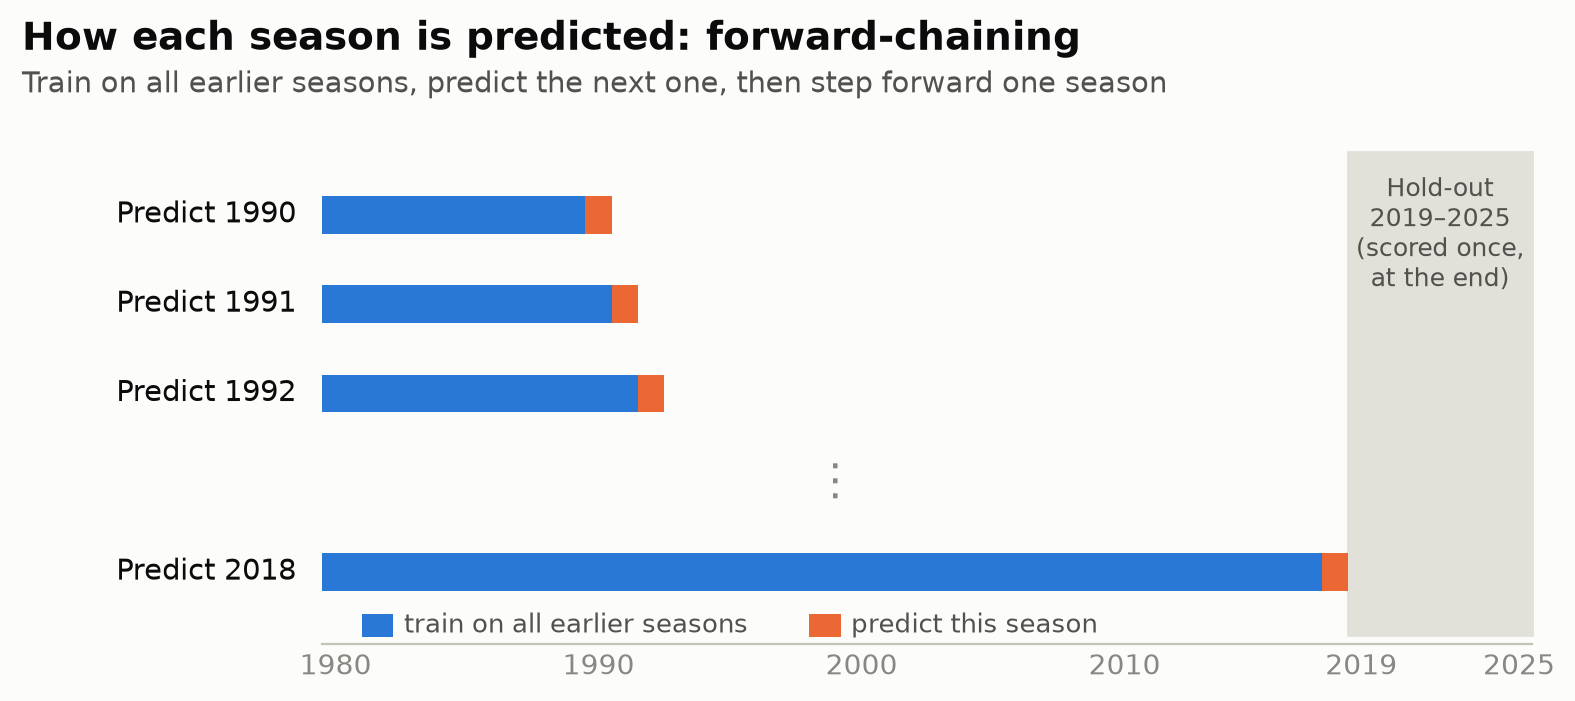

In [33]:
#forward-chaining diagram
from matplotlib.patches import Rectangle


def plot_forward_chaining(fname, start=1980, hold=HOLDOUT_START, end=2025):
    #rows: a few example test seasons; None draws the "..." gap
    rows = [(1990, 'Predict 1990'), (1991, 'Predict 1991'), (1992, 'Predict 1992'), (None, '...'), (2018, 'Predict 2018')]
    fig, ax = plt.subplots(figsize=(8, 3.6), dpi=200)
    fig.patch.set_facecolor(SURFACE); ax.set_facecolor(SURFACE)

    #shaded hold-out block
    ax.add_patch(Rectangle((hold - 0.5, -0.7), end - hold + 1, len(rows) + 0.4, color=GRID, zorder=0))
    ax.text(hold + (end - hold) / 2, len(rows) - 0.55, f'Hold-out\n{hold}–{end}\n(scored once,\nat the end)',
            ha='center', va='top', fontsize=9, color=INK2)

    for i, (yr, label) in enumerate(rows):
        y = len(rows) - 1 - i                                   #top row first
        if yr is None:
            ax.text(1999, y, '⋮', ha='center', va='center', fontsize=16, color=MUTED)
            continue
        ax.barh(y, yr - start, left=start - 0.5, height=0.42, color=BLUE)     #training seasons
        ax.barh(y, 1, left=yr - 0.5, height=0.42, color=ORANGE)               #the predicted season
        ax.text(start - 1.5, y, label, ha='right', va='center', fontsize=10.5, color=INK)

    ax.set_xlim(start - 12, end + 1); ax.set_ylim(-0.8, len(rows) - 0.2)
    ax.set_yticks([]); ax.set_xticks([1980, 1990, 2000, 2010, hold, end])
    for side in ['top', 'right', 'left']:
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(AXIS); ax.spines['bottom'].set_bounds(start - 0.5, end + 0.5)
    ax.tick_params(colors=MUTED, length=0)

    #legend drawn as small bars, so it matches the marks exactly
    ax.barh(-0.6, 1.2, left=1981, height=0.25, color=BLUE)
    ax.text(1982.6, -0.6, 'train on all earlier seasons', va='center', fontsize=9.5, color=INK2)
    ax.barh(-0.6, 1.2, left=1998, height=0.25, color=ORANGE)
    ax.text(1999.6, -0.6, 'predict this season', va='center', fontsize=9.5, color=INK2)

    add_titles(fig, 'How each season is predicted: forward-chaining',
               'Train on all earlier seasons, predict the next one, then step forward one season')
    fig.tight_layout(rect=(0, 0, 1, 0.83))
    fig.savefig(OUT / fname, facecolor=SURFACE)
    plt.show()

plot_forward_chaining('forward_chaining.png')


### B. How often each model picks the MVP
**Main KPI:** seasons where the model's #1 pick was the real MVP. **Secondary:** seasons where the real MVP was in the model's top 3.
Result: the conditional logit picks 13/18, gradient boosting 12/18, the quasi-binomial 11/18, and the "top scorer wins" baseline 4/18.

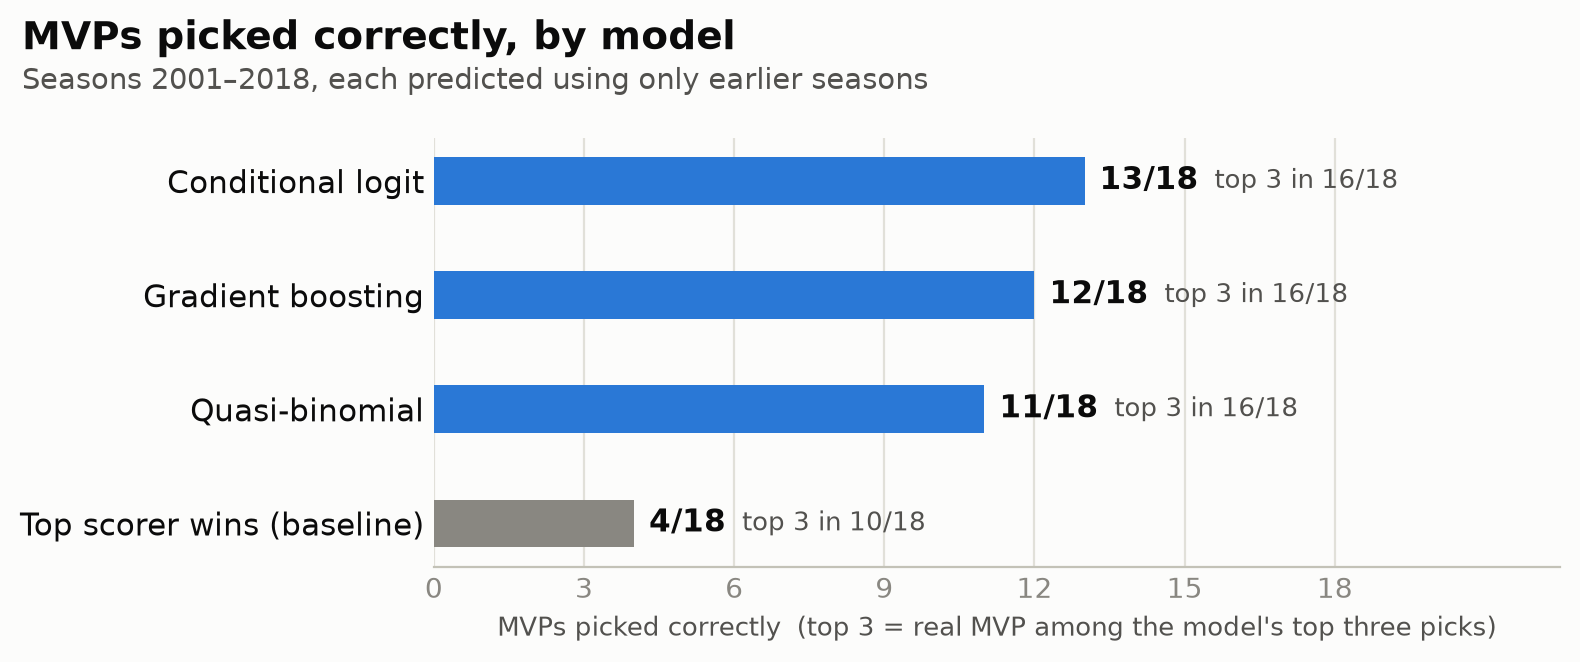

In [34]:
#how many MVPs each model picked correctly (and how often the real MVP was in its top 3)
def score(df, col):
    #hits = real MVP ranked 1st; top3 = real MVP ranked in the model's top 3
    hits, top3 = 0, 0
    for yr, g in df.groupby('Year'):
        actual = g.loc[g['MVP'].idxmax(), 'Code']
        order = g.sort_values(col, ascending=False)['Code'].tolist()
        rank = order.index(actual) + 1
        hits += rank == 1
        top3 += rank <= 3
    return hits, df['Year'].nunique(), top3

def plot_model_comparison(df, models, main, sub, fname):
    rows = [(label, *score(df, col)) for label, col in models.items()]
    fig, ax = new_chart((8, 3.4))
    bars = ax.barh([r[0] for r in rows], [r[1] for r in rows], height=0.42,
                   color=[MUTED if 'baseline' in r[0] else BLUE for r in rows])
    for b, (label, hits, n, top3) in zip(bars, rows):
        t = ax.text(hits + 0.3, b.get_y() + b.get_height()/2, f'{hits}/{n}',
                    va='center', color=INK, fontsize=11, fontweight='bold')
        ax.annotate(f'  top 3 in {top3}/{n}', xy=(1, 0.5), xycoords=t, va='center', color=INK2, fontsize=9.5)
    n = rows[0][2]
    ax.set_xlim(0, n + 4.5); ax.set_xticks(range(0, n + 1, 3))
    ax.tick_params(axis='y', colors=INK, labelsize=11)
    ax.set_xlabel("MVPs picked correctly  (top 3 = real MVP among the model's top three picks)", color=INK2, fontsize=9.5)
    add_titles(fig, main, sub)
    fig.tight_layout(rect=(0, 0, 1, 0.83))
    fig.savefig(OUT / fname, facecolor=SURFACE)
    plt.show()

#bottom-to-top order on the chart
models = {'Top scorer wins (baseline)': 'PTS',
          'Quasi-binomial': 'pred_candidates_10',
          'Gradient boosting': 'gbr_raw_candidates_10',
          'Conditional logit': 'clogit_candidates_10'}
#the three models without the baseline, with short tags for file names
short = {'Quasi-binomial': 'quasi', 'Gradient boosting': 'gb', 'Conditional logit': 'clogit'}
window = data[(data['Year'] >= 2001) & data['Year'].isin(test_years)]
plot_model_comparison(window, models,
                      'MVPs picked correctly, by model',
                      'Seasons 2001–2018, each predicted using only earlier seasons',
                      'model_comparison_2001_2018.png')

In [35]:
#vote-share error: for each season's real top-5 vote-getters, how far off was the predicted vote share?
#(forward-chained predictions, 2001-2018; only the vote-share models, since the clogit doesn't predict vote share)
def top5_error(df, col):
    """Average |predicted - actual| vote share over each season's actual top 5 vote-getters."""
    top5 = df.sort_values('MVPVS', ascending=False).groupby('Year').head(5)
    return (top5[col] - top5['MVPVS']).abs().mean()

for name in ['Quasi-binomial', 'Gradient boosting']:
    print(f'{name}: off by {top5_error(window, models[name]):.3f} vote share on average (top 5, 2001-2018)')

Quasi-binomial: off by 0.183 vote share on average (top 5, 2001-2018)
Gradient boosting: off by 0.226 vote share on average (top 5, 2001-2018)


In [36]:
#direction of the error: negative = the model predicts too little vote share for the top 5
top5 = window.sort_values('MVPVS', ascending=False).groupby('Year').head(5)
for name in ['Quasi-binomial', 'Gradient boosting']:
    print(f'{name}: average (predicted - actual) = {(top5[models[name]] - top5["MVPVS"]).mean():+.3f}')

Quasi-binomial: average (predicted - actual) = -0.028
Gradient boosting: average (predicted - actual) = -0.177


**Vote-share accuracy (2001–2018, each season's top 5 vote-getters):** the quasi-binomial is off by 0.18 on average and nearly unbiased (−0.03); gradient boosting is off by 0.23, almost all of it underprediction (−0.18). Gradient boosting ranks players well (it picks the MVP more often) but underestimates how much of the vote the top candidates get.

### C. Which seasons each model missed
One table per model (who it picked, their points / team win %, and where it ranked the real MVP), then one table with every model's misses side by side.
All three models missed 2004–05 and 2005–06 (Nash) and 2016–17 (Westbrook). Those are seasons where voters rewarded something our stats don't capture well (a pass-first point guard, a triple-double season).
2014–15 (Curry) is missed by both the quasi-binomial and gradient boosting, which picked Harden; only the conditional logit got it.
Gradient boosting also misses 2006–07: it picks Nash over Dirk on assists and 3-pointers, in the season voters went the other way.

In [37]:
#misses table
def misses_table(df, col):
    """Seasons where the model's top pick wasn't the real MVP: who it picked, who won, and where it ranked the winner."""
    rows = []
    for yr, g in df.groupby('Year'):
        g = g.sort_values(col, ascending=False).reset_index(drop=True)   #row 0 = model's top pick
        winner = g[g['MVP'] == 1].iloc[0]
        pick = g.iloc[0]
        if pick['Code'] != winner['Code']:
            rows.append({'Season': f"{yr}–{str(yr + 1)[-2:]}",            #e.g. 2004 -> "2004–05"
                         'Model picked': pick['Player'],
                         'Picked: PTS / W%': f"{pick['PTS']:.1f} / {pick['W%']:.3f}",
                         'Actual MVP': winner['Player'],
                         'MVP: PTS / W%': f"{winner['PTS']:.1f} / {winner['W%']:.3f}",
                         "MVP's rank in model": int(g.index[g['Code'] == winner['Code']][0]) + 1})
    return pd.DataFrame(rows)

In [38]:
#misses table for every model (same seasons as the comparison chart)

for name, col in models.items():
    if name not in short:          #skip the baseline
        continue
    m = misses_table(window, col)
    m.to_csv(OUT / f'misses_{short[name]}_2001_2018.csv', index=False)
    print(f'\n===== {name}: missed {len(m)} of {window["Year"].nunique()} seasons')
    display(m)


===== Quasi-binomial: missed 7 of 18 seasons


,Season,Model picked,Picked: PTS / W%,Actual MVP,MVP: PTS / W%,MVP's rank in model
0,2002–03,Kobe Bryant,30.0 / 0.610,Tim Duncan,23.3 / 0.732,2
1,2004–05,Dirk Nowitzki,26.1 / 0.707,Steve Nash,15.5 / 0.756,11
2,2005–06,LeBron James,31.4 / 0.610,Steve Nash,18.8 / 0.659,7
3,2010–11,LeBron James,26.7 / 0.707,Derrick Rose,25.0 / 0.756,2
4,2014–15,James Harden,27.4 / 0.683,Stephen Curry,23.8 / 0.817,2
5,2016–17,James Harden,29.1 / 0.671,Russell Westbrook,31.6 / 0.573,2
6,2018–19,James Harden,36.1 / 0.646,Giannis Antetokounmpo,27.7 / 0.732,2



===== Gradient boosting: missed 6 of 18 seasons


,Season,Model picked,Picked: PTS / W%,Actual MVP,MVP: PTS / W%,MVP's rank in model
0,2002–03,Kobe Bryant,30.0 / 0.610,Tim Duncan,23.3 / 0.732,2
1,2004–05,Amar'e Stoudemire,26.0 / 0.756,Steve Nash,15.5 / 0.756,12
2,2005–06,LeBron James,31.4 / 0.610,Steve Nash,18.8 / 0.659,12
3,2006–07,Steve Nash,18.6 / 0.744,Dirk Nowitzki,24.6 / 0.817,2
4,2014–15,James Harden,27.4 / 0.683,Stephen Curry,23.8 / 0.817,2
5,2016–17,Stephen Curry,25.3 / 0.817,Russell Westbrook,31.6 / 0.573,3



===== Conditional logit: missed 5 of 18 seasons


,Season,Model picked,Picked: PTS / W%,Actual MVP,MVP: PTS / W%,MVP's rank in model
0,2004–05,Dirk Nowitzki,26.1 / 0.707,Steve Nash,15.5 / 0.756,6
1,2005–06,Chauncey Billups,18.5 / 0.780,Steve Nash,18.8 / 0.659,8
2,2011–12,Kevin Durant,28.0 / 0.712,LeBron James,27.1 / 0.697,2
3,2016–17,James Harden,29.1 / 0.671,Russell Westbrook,31.6 / 0.573,3
4,2018–19,James Harden,36.1 / 0.646,Giannis Antetokounmpo,27.7 / 0.732,2


In [39]:
#one table: each season at least one model missed, and who each model picked instead
rows = {}
for yr, g in window.groupby('Year'):
    rows[yr] = {'Actual MVP': g.loc[g['MVP'] == 1, 'Player'].iloc[0]}
    for name in short:
        pick = g.loc[g[models[name]].idxmax()]
        rows[yr][name] = '✓' if pick['MVP'] == 1 else pick['Player']

grid = pd.DataFrame.from_dict(rows, orient='index')
grid = grid[(grid[list(short)] != '✓').any(axis=1)]          #drop seasons all models got right
grid.index = [f"{y}–{str(y + 1)[-2:]}" for y in grid.index]   #2004 -> "2004–05"
grid.to_csv(OUT / 'misses_all_models_2001_2018.csv')
grid

,Actual MVP,Quasi-binomial,Gradient boosting,Conditional logit
2002–03,Tim Duncan,Kobe Bryant,Kobe Bryant,✓
2004–05,Steve Nash,Dirk Nowitzki,Amar'e Stoudemire,Dirk Nowitzki
2005–06,Steve Nash,LeBron James,LeBron James,Chauncey Billups
2006–07,Dirk Nowitzki,✓,Steve Nash,✓
2010–11,Derrick Rose,LeBron James,✓,✓
2011–12,LeBron James,✓,✓,Kevin Durant
2014–15,Stephen Curry,James Harden,James Harden,✓
2016–17,Russell Westbrook,James Harden,Stephen Curry,James Harden
2018–19,Giannis Antetokounmpo,James Harden,✓,James Harden


### D. What each model learned (1980–2018)
One chart per model, each fit on all development seasons **with** MVP_recency. These show what each model learned overall, not the season-by-season picks.

The three charts measure different things, so compare the order of the stats, not the numbers:
- **Conditional logit:** effect on the chance of *winning* (log-odds per 1 SD above the season average).
- **Quasi-binomial:** effect on *vote share*. With ~6,300 player-seasons every range is narrow, so judge by size, not color.
- **Gradient boosting:** permutation importance, meaning how much the fit drops when a stat is shuffled. It has no direction (it can't say whether a stat helps or hurts).

All three agree that team win % and points matter most.

In [40]:
#shared chart for "what each model learned": one dot + 95% range per stat, sorted, blue if the range is clear of zero
names = {'PTS_z': 'Points', 'W%_z': 'Team win %', 'FT_z': 'Free throws', 'eFG%_z': 'Shooting efficiency (eFG%)',
         'DRB_z': 'Defensive rebounds', 'AST_z': 'Assists', 'BLK_z': 'Blocks', 'STL_z': 'Steals',
         'GS_z': 'Games started', '3P_z': '3-pointers', 'MVP_recency': 'Recent MVP wins (per win)'}
def label(f):
    return names.get(f, names.get(f + '_z', f))

def plot_ranges(c, xlabel, main, sub, fname):
    # c: DataFrame indexed by feature, with columns est, lo, hi
    c = c.sort_values('est')
    clear = (c['lo'] > 0) | (c['hi'] < 0)          # range doesn't cross zero
    fig, ax = new_chart((8, 4.6))
    ax.axvline(0, color=AXIS, linewidth=1.2, zorder=1)
    for i, (feat, r) in enumerate(c.iterrows()):
        col = BLUE if clear[feat] else MUTED
        ax.plot([r.lo, r.hi], [i, i], color=col, linewidth=2, solid_capstyle='round', zorder=2)
        ax.scatter(r.est, i, s=70, color=col, edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.set_yticks(range(len(c)))
    ax.set_yticklabels([label(f) for f in c.index])
    for lab, feat in zip(ax.get_yticklabels(), c.index):
        lab.set_color(INK if clear[feat] else MUTED)
    ax.set_xlabel(xlabel, color=INK2, fontsize=9.5)
    add_titles(fig, main, sub)
    fig.tight_layout(rect=(0, 0, 1, 0.87))
    fig.savefig(OUT / fname, facecolor=SURFACE)
    plt.show()

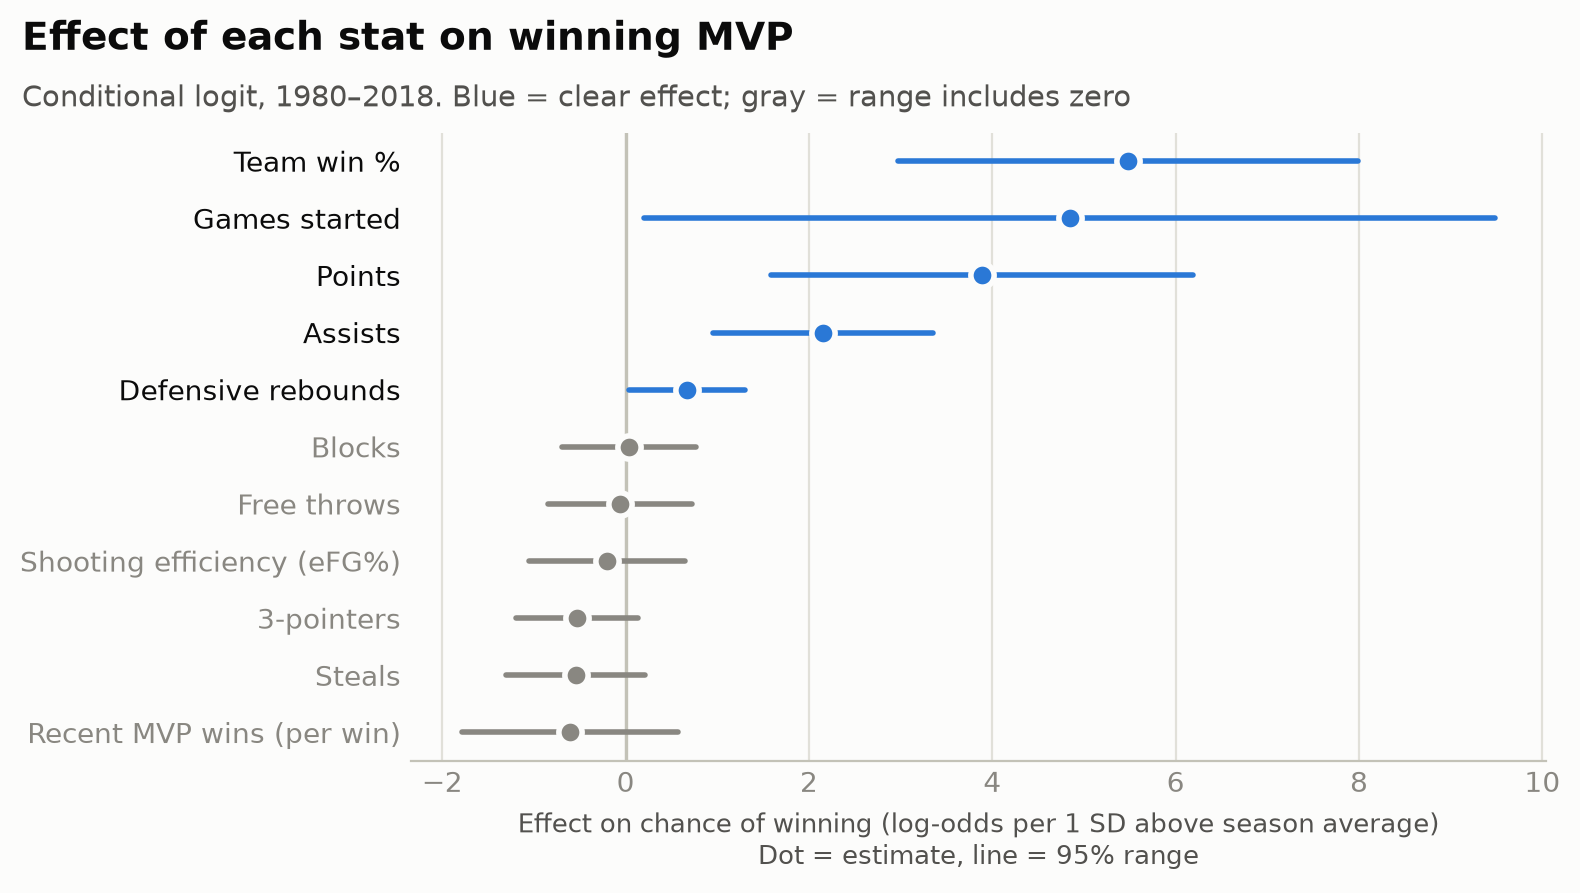

In [41]:
#conditional logit: effect of each stat on winning
ci = clogit.conf_int()
c = pd.DataFrame({'est': clogit.params, 'lo': ci[0], 'hi': ci[1]})
plot_ranges(c,
    'Effect on chance of winning (log-odds per 1 SD above season average)\nDot = estimate, line = 95% range',
    'Effect of each stat on winning MVP',
    'Conditional logit, 1980–2018. Blue = clear effect; gray = range includes zero',
    'what_wins_mvp.png')

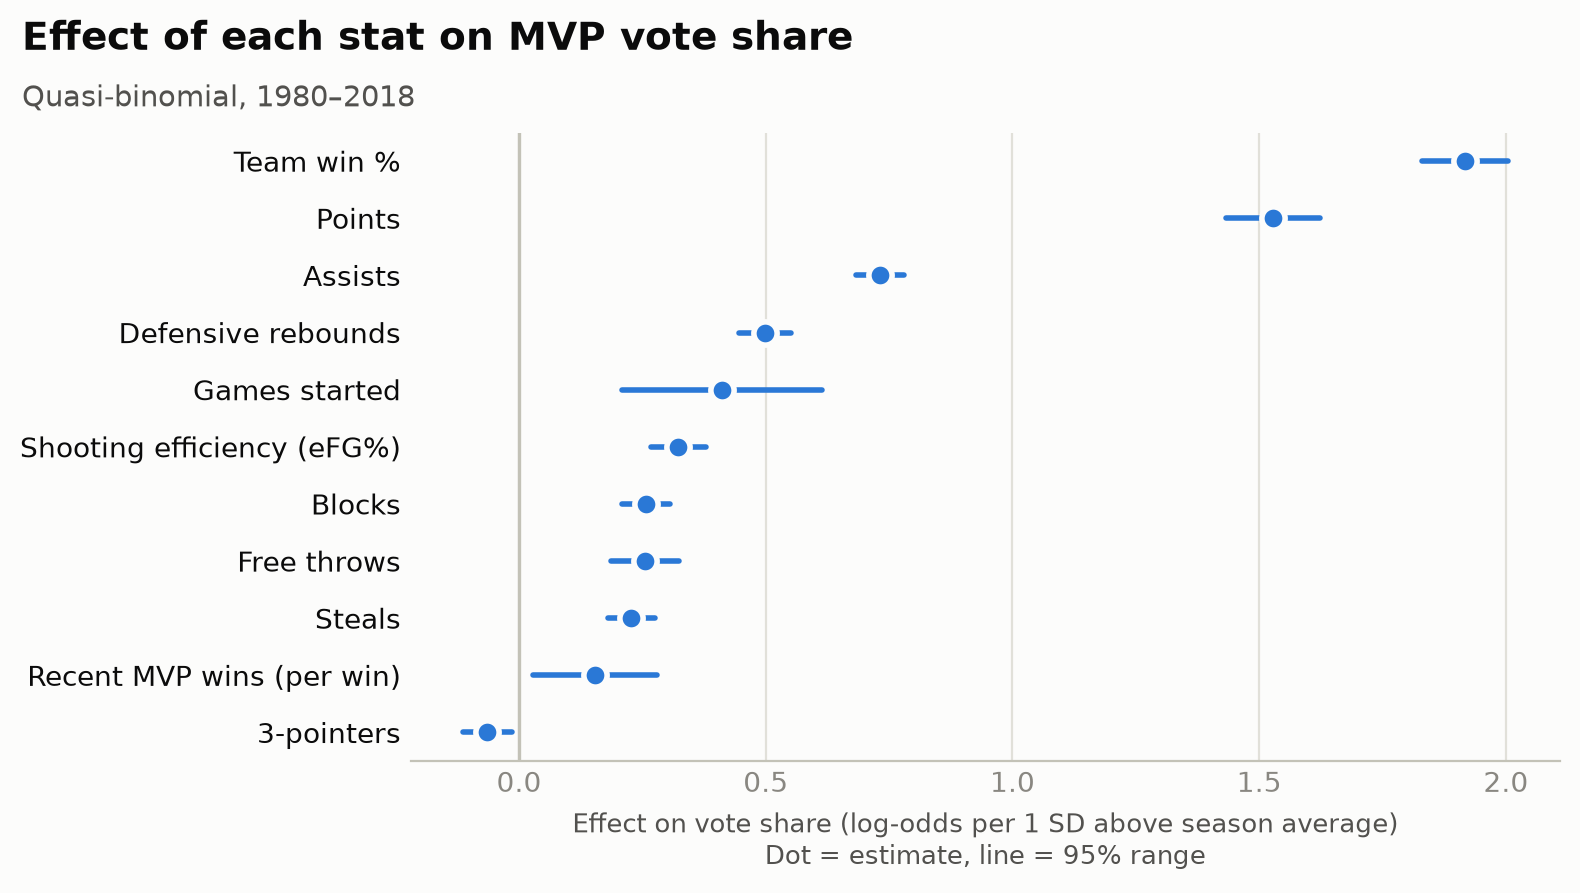

In [42]:
ci = qb_all.conf_int()
c = pd.DataFrame({'est': qb_all.params, 'lo': ci[0], 'hi': ci[1]}).drop('const')

plot_ranges(c,
    'Effect on vote share (log-odds per 1 SD above season average)\nDot = estimate, line = 95% range',
    'Effect of each stat on MVP vote share',
    'Quasi-binomial, 1980–2018',
    'effects_quasi.png')

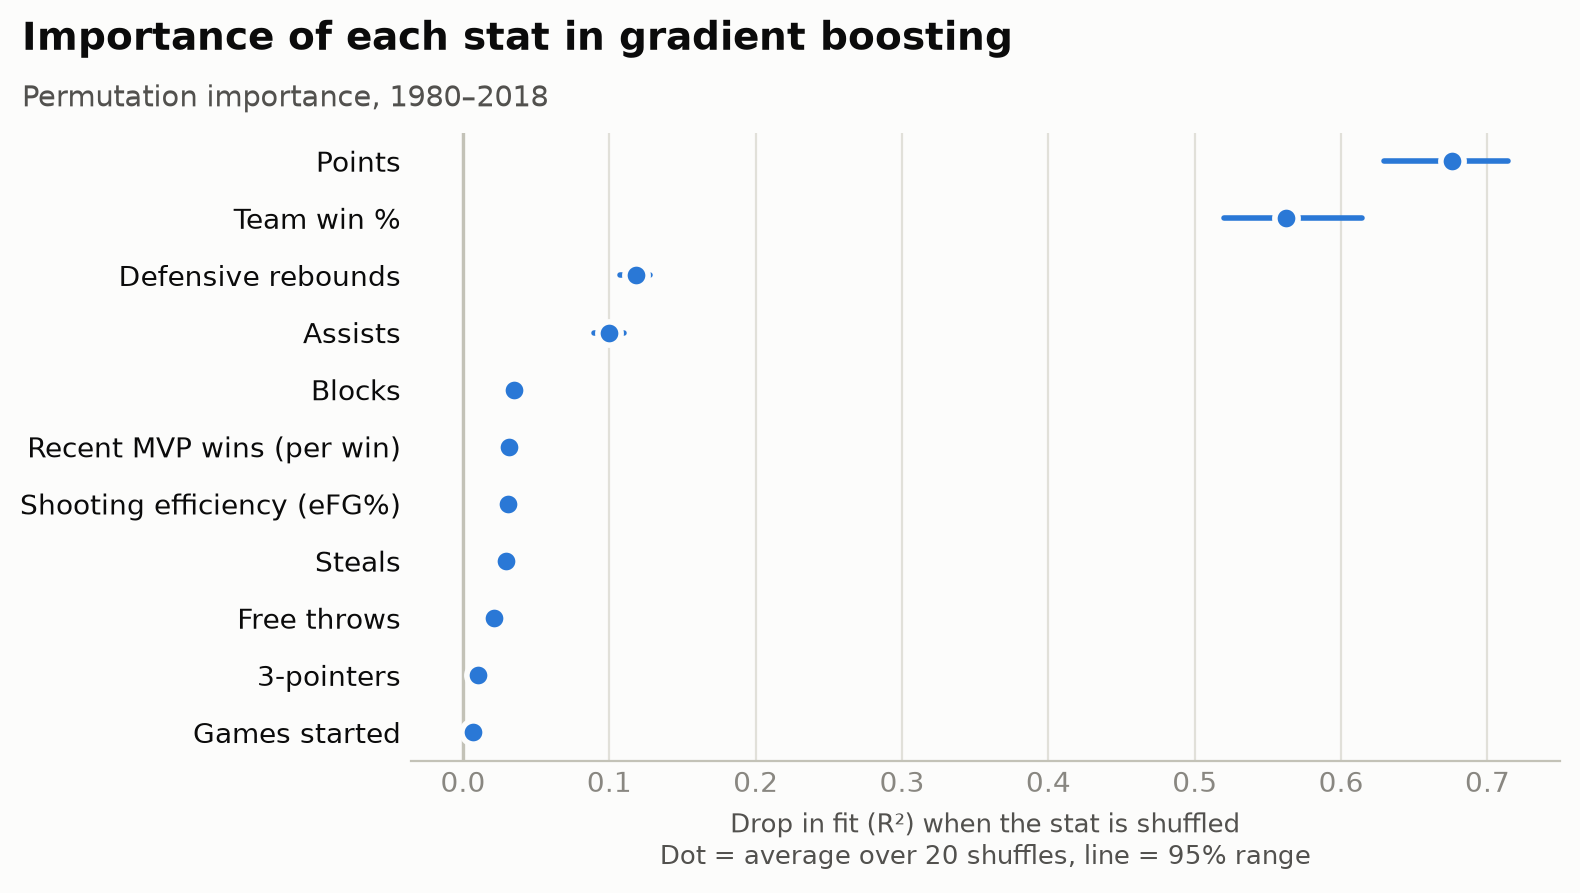

In [43]:
from sklearn.inspection import permutation_importance

gcols = feature_sets['candidates_10'] + ['MVP_recency']     # raw candidates_10, same as gbr_raw_candidates_10
gb = HistGradientBoostingRegressor(random_state=12,**BEST_GBR).fit(data[gcols], data['MVPVS'])
#measured on the training seasons, so it shows what the model relies on, not how well it predicts
r = permutation_importance(gb, data[gcols], data['MVPVS'], n_repeats=20, random_state=12)

c = pd.DataFrame({'est': r.importances_mean,
                  'lo':  np.percentile(r.importances, 2.5, axis=1),
                  'hi':  np.percentile(r.importances, 97.5, axis=1)}, index=gcols)

plot_ranges(c,
    'Drop in fit (R²) when the stat is shuffled\nDot = average over 20 shuffles, line = 95% range',
    'Importance of each stat in gradient boosting',
    'Permutation importance, 1980–2018',
    'importance_gb.png')

### E. Why each model picked who it picked
Every model gives each player a score, and the pick is the highest score. Each score splits exactly into one piece per stat: coefficient × z-score for the two linear models, SHAP values for gradient boosting. We use the model that actually made each season's pick (trained only on earlier seasons), and check that it reproduces the predictions above.

Requires `shap` (`conda install -c conda-forge shap`).

In [44]:
#refit the exact models behind the comparison chart (candidates_10, no MVP_recency), one per test season, and keep them
feats10 = feature_sets['candidates_10']        #raw stats, for gradient boosting
z10 = [c + '_z' for c in feats10]              #z-scores, for quasi-binomial and conditional logit

season_models = {}     #season -> {model name: model trained only on earlier seasons}
for yr in test_years:
    train = data['Year'] < yr
    assert data.loc[train, 'Year'].max() < yr
    season_models[yr] = {
        'Quasi-binomial': sm.GLM(data.loc[train, 'MVPVS'], sm.add_constant(data.loc[train, z10]),
                                 family=sm.families.Binomial()).fit(scale='X2'),
        'Gradient boosting': HistGradientBoostingRegressor(random_state=12,**BEST_GBR)
                             .fit(data.loc[train, feats10], data.loc[train, 'MVPVS']),
        'Conditional logit': ConditionalLogit(data.loc[train, 'MVP'], data.loc[train, z10],
                                              groups=data.loc[train, 'Year'])
                             .fit(disp=False, skip_hessian=True, maxiter=200),
    }
print(len(season_models), 'seasons stored')

29 seasons stored


In [45]:
#check: the stored models must reproduce the predictions already in data, or the breakdown would explain picks that never happened
for yr in test_years:
    g = data[data['Year'] == yr]
    m = season_models[yr]
    assert np.allclose(m['Quasi-binomial'].predict(sm.add_constant(g[z10], has_constant='add')), g['pred_candidates_10'])
    assert np.allclose(m['Gradient boosting'].predict(g[feats10]), g['gbr_raw_candidates_10'])
    assert np.allclose(g[z10] @ m['Conditional logit'].params, g['clogit_candidates_10'])
print('all', len(test_years), 'seasons match')

all 29 seasons match


In [46]:
#split each player's score into one piece per stat (coefficient x z-score for the linear models, SHAP for gradient boosting)
import shap

def contributions(yr, name):
    """One row per player in season yr, one column per stat: how much that stat added to the player's score
    under the model that made that season's pick. The pieces add up to the score (plus a constant shared by everyone)."""
    g = data[data['Year'] == yr]
    m = season_models[yr][name]
    if name == 'Gradient boosting':
        vals = shap.TreeExplainer(m).shap_values(g[feats10])     #SHAP: exact split for tree models
        return pd.DataFrame(vals, index=g.index, columns=feats10)
    coefs = m.params[z10].values                                 #linear models: piece = coefficient x z-score
    return pd.DataFrame(g[z10].values * coefs, index=g.index, columns=feats10)

In [47]:
#check: for one season, the pieces must add up to each model's score
yr = 2016
g = data[data['Year'] == yr]
for name in short:
    m = season_models[yr][name]
    total = contributions(yr, name).sum(axis=1)
    if name == 'Quasi-binomial':
        p = g['pred_candidates_10']
        target = np.log(p / (1 - p)) - m.params['const']         #back to log-odds, minus the shared constant
    elif name == 'Gradient boosting':
        target = g['gbr_raw_candidates_10'] - shap.TreeExplainer(m).expected_value
    else:
        target = g['clogit_candidates_10']
    print(name, np.allclose(total, target))

Quasi-binomial True
Gradient boosting True
Conditional logit True


In [48]:
#what decides each model's pick: model's #1 vs its #2 every season, as each stat's share of the winning margin
def deciding_shares(name, years):
    gaps = []
    for yr in years:
        g = data[data['Year'] == yr]
        top2 = g[models[name]].sort_values(ascending=False).index[:2]    #model's 1st and 2nd pick
        c = contributions(yr, name)
        gaps.append(c.loc[top2[0]] - c.loc[top2[1]])                     #per-stat gap; sums to the winning margin
    gaps = pd.DataFrame(gaps)
    return gaps.sum() / gaps.sum().sum()          #each stat's share of the total margin over all seasons

dev_years = [yr for yr in test_years if yr >= 2001]
shares = pd.DataFrame({name: deciding_shares(name, dev_years) for name in short})
(shares * 100).round(1)

,Quasi-binomial,Gradient boosting,Conditional logit
PTS,41.8,57.1,43.3
W%,22.8,30.0,48.7
FT,13.1,3.3,2.6
eFG%,-2.3,-3.2,-4.2
DRB,1.1,-3.4,9.1
AST,16.5,11.3,3.3
BLK,-6.2,0.7,2.8
STL,11.0,2.4,1.8
GS,2.8,0.4,3.7
3P,-0.5,1.3,-11.0


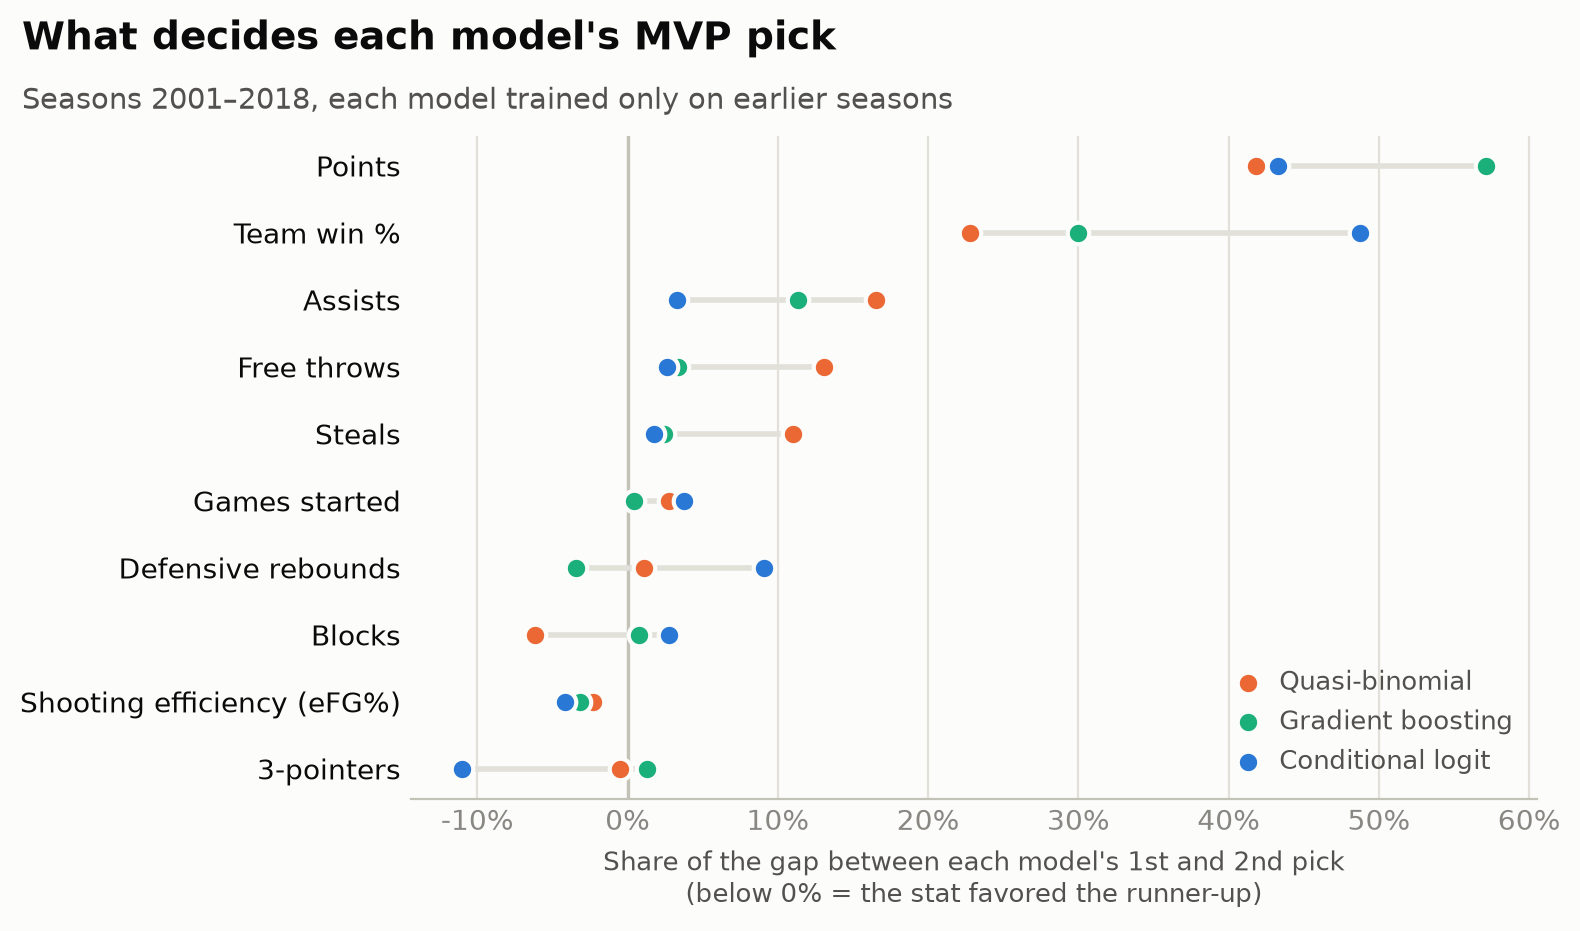

In [49]:
MODEL_COLORS = {'Quasi-binomial': ORANGE, 'Gradient boosting': AQUA, 'Conditional logit': BLUE}

def plot_deciding(shares, main, sub, fname):
    shares = shares.loc[shares.mean(axis=1).sort_values().index] * 100     #biggest on top
    fig, ax = new_chart((8, 4.8))
    ax.axvline(0, color=AXIS, linewidth=1.2, zorder=1)
    for i, feat in enumerate(shares.index):                                 #gray bar = how much the models disagree
        ax.plot([shares.loc[feat].min(), shares.loc[feat].max()], [i, i], color=GRID, linewidth=2, zorder=1)
    for name, color in MODEL_COLORS.items():
        ax.scatter(shares[name], range(len(shares)), s=60, color=color, edgecolor=SURFACE,
                   linewidth=1.5, zorder=3, label=name)
    ax.set_yticks(range(len(shares)))
    ax.set_yticklabels([label(f) for f in shares.index], color=INK)
    ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
    ax.set_xlabel("Share of the gap between each model's 1st and 2nd pick\n(below 0% = the stat favored the runner-up)",
                  color=INK2, fontsize=9.5)
    ax.legend(loc='lower right', frameon=False, fontsize=9.5, labelcolor=INK2, handletextpad=0.2)
    add_titles(fig, main, sub)
    fig.tight_layout(rect=(0, 0, 1, 0.87))
    fig.savefig(OUT / fname, facecolor=SURFACE)
    plt.show()

plot_deciding(shares, "What decides each model's MVP pick",
              'Seasons 2001–2018, each model trained only on earlier seasons', 'deciding_stats.png')

Team win % and points decide most picks in every model (together ~65% of the margin for the quasi-binomial, ~87% for gradient boosting and ~92% for the conditional logit). The conditional logit leans hardest on winning (~49%), while gradient boosting leans on points (~57%) with winning second (~30%), and the quasi-binomial spreads the decision across assists, free throws and steals (winning only ~23%). The conditional logit also marks down 3-point volume (about −11%). our reading: the quasi-binomial learns what gets a player *any* votes, while the conditional logit learns what separates #1 from #2.

In [50]:
#one season, all three models. Each panel compares the real MVP (blue, left) with one other player:
#the model's pick if it was wrong, or its runner-up if it was right. If blue outweighs orange, the model picked the MVP.
def plot_case(yr, fname=None):
    g = data[data['Year'] == yr]
    mvp = g['MVP'].idxmax()
    mvp_name = g.loc[mvp, 'Player']
    season = f"{yr}–{str(yr + 1)[-2:]}"
    diffs, titles, n_hits = {}, {}, 0
    for name in short:
        ranked = g[models[name]].sort_values(ascending=False).index
        if ranked[0] == mvp:                               #right: compare with the model's runner-up
            other = ranked[1]
            n_hits += 1
            titles[name] = f"{name}: ✓ right\npicked {mvp_name}\nrunner-up: {g.loc[other, 'Player']}"
        else:                                              #wrong: compare with the player it picked
            other = ranked[0]
            titles[name] = f"{name}: ✗ wrong\npicked {g.loc[other, 'Player']}"
        c = contributions(yr, name)
        diffs[name] = c.loc[other] - c.loc[mvp]            #positive = favored the other player, negative = favored the MVP
    diffs = pd.DataFrame(diffs)
    #same stat order in every panel, biggest combined effect on top
    order = diffs.abs().div(diffs.abs().max()).sum(axis=1).sort_values().index

    fig, axes = plt.subplots(1, 3, figsize=(11, 4.8), sharey=True, dpi=200)
    fig.patch.set_facecolor(SURFACE)
    for ax, name in zip(axes, short):
        ax.set_facecolor(SURFACE)
        for side in ['top', 'right', 'left', 'bottom']:
            ax.spines[side].set_visible(False)
        ax.tick_params(length=0, colors=INK)
        ax.set_xticks([])                                  #units differ by model, so no shared scale
        ax.axvline(0, color=AXIS, linewidth=1.2)
        d = diffs.loc[order, name]
        ax.barh(range(len(d)), d, height=0.6, color=[ORANGE if v > 0 else BLUE for v in d])
        lim = d.abs().max() * 1.15
        ax.set_xlim(-lim, lim)                             #center the zero line so left/right look balanced
        ax.set_title(titles[name], fontsize=10, color=INK, loc='left')
    axes[0].set_yticks(range(len(order)))
    axes[0].set_yticklabels([label(f) for f in order])
    add_titles(fig, f"How each model picked the {season} MVP",
               f"Real MVP: {mvp_name} (blue, left). {n_hits} of 3 models picked him")
    fig.text(0.02, 0.02, f"Blue (left) = stat favored {mvp_name}; orange (right) = favored the other player in that panel. "
             "Bar sizes compare within a model only", fontsize=9, color=INK2)
    fig.tight_layout(rect=(0, 0.05, 1, 0.84))
    fig.savefig(OUT / (fname or f'how_picked_{yr}.png'), facecolor=SURFACE)
    plt.show()

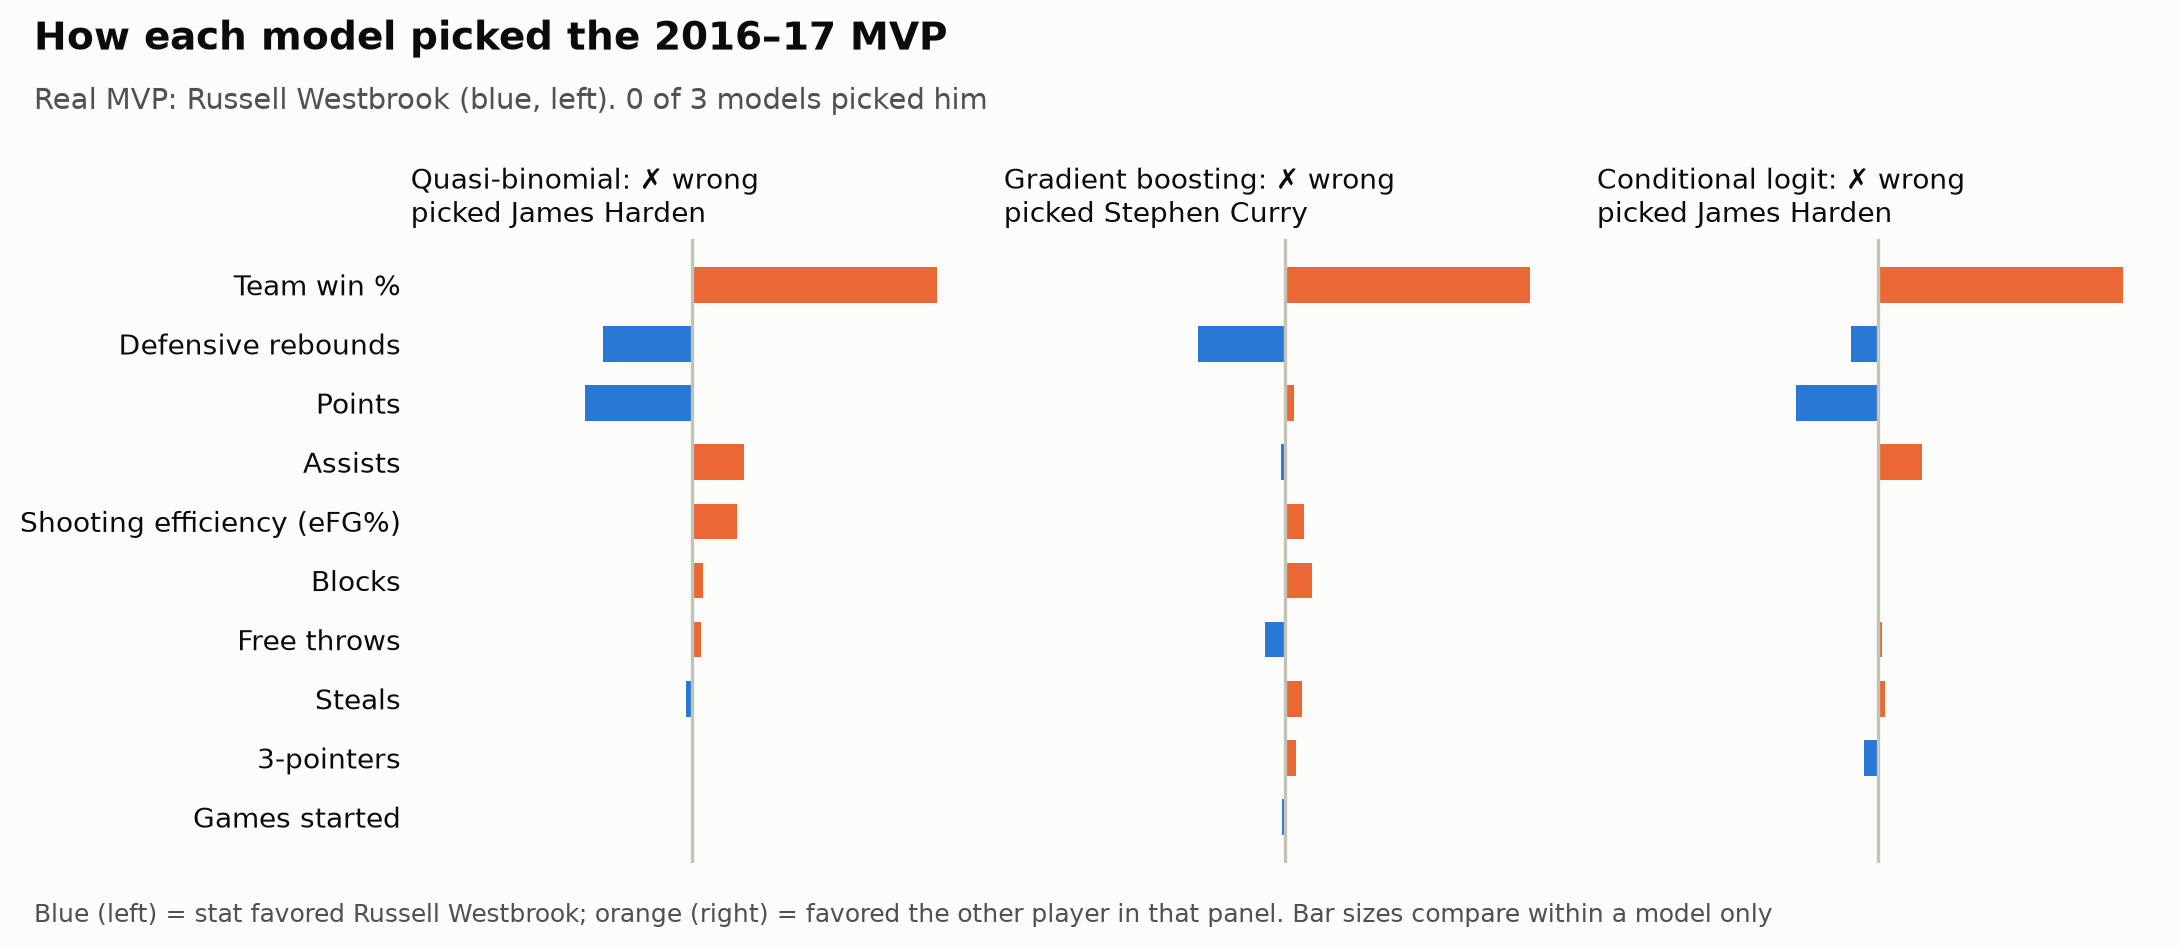

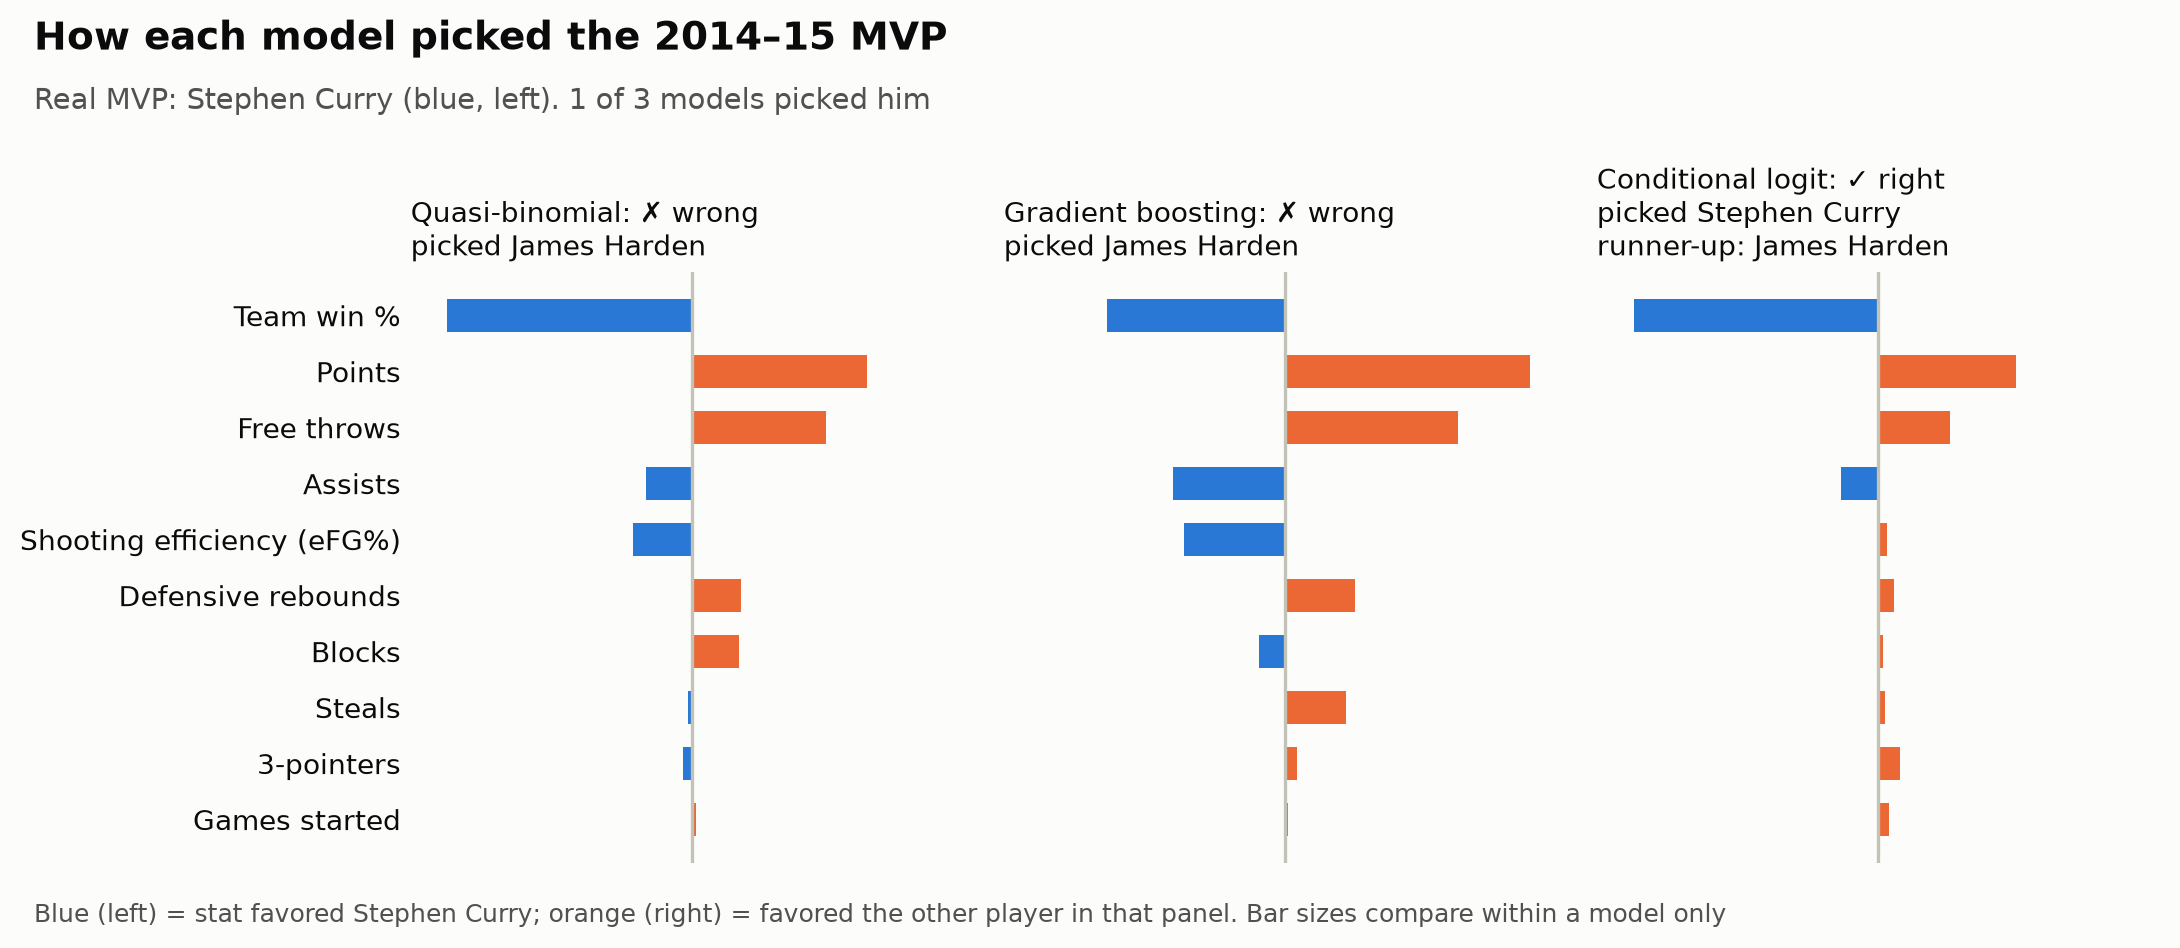

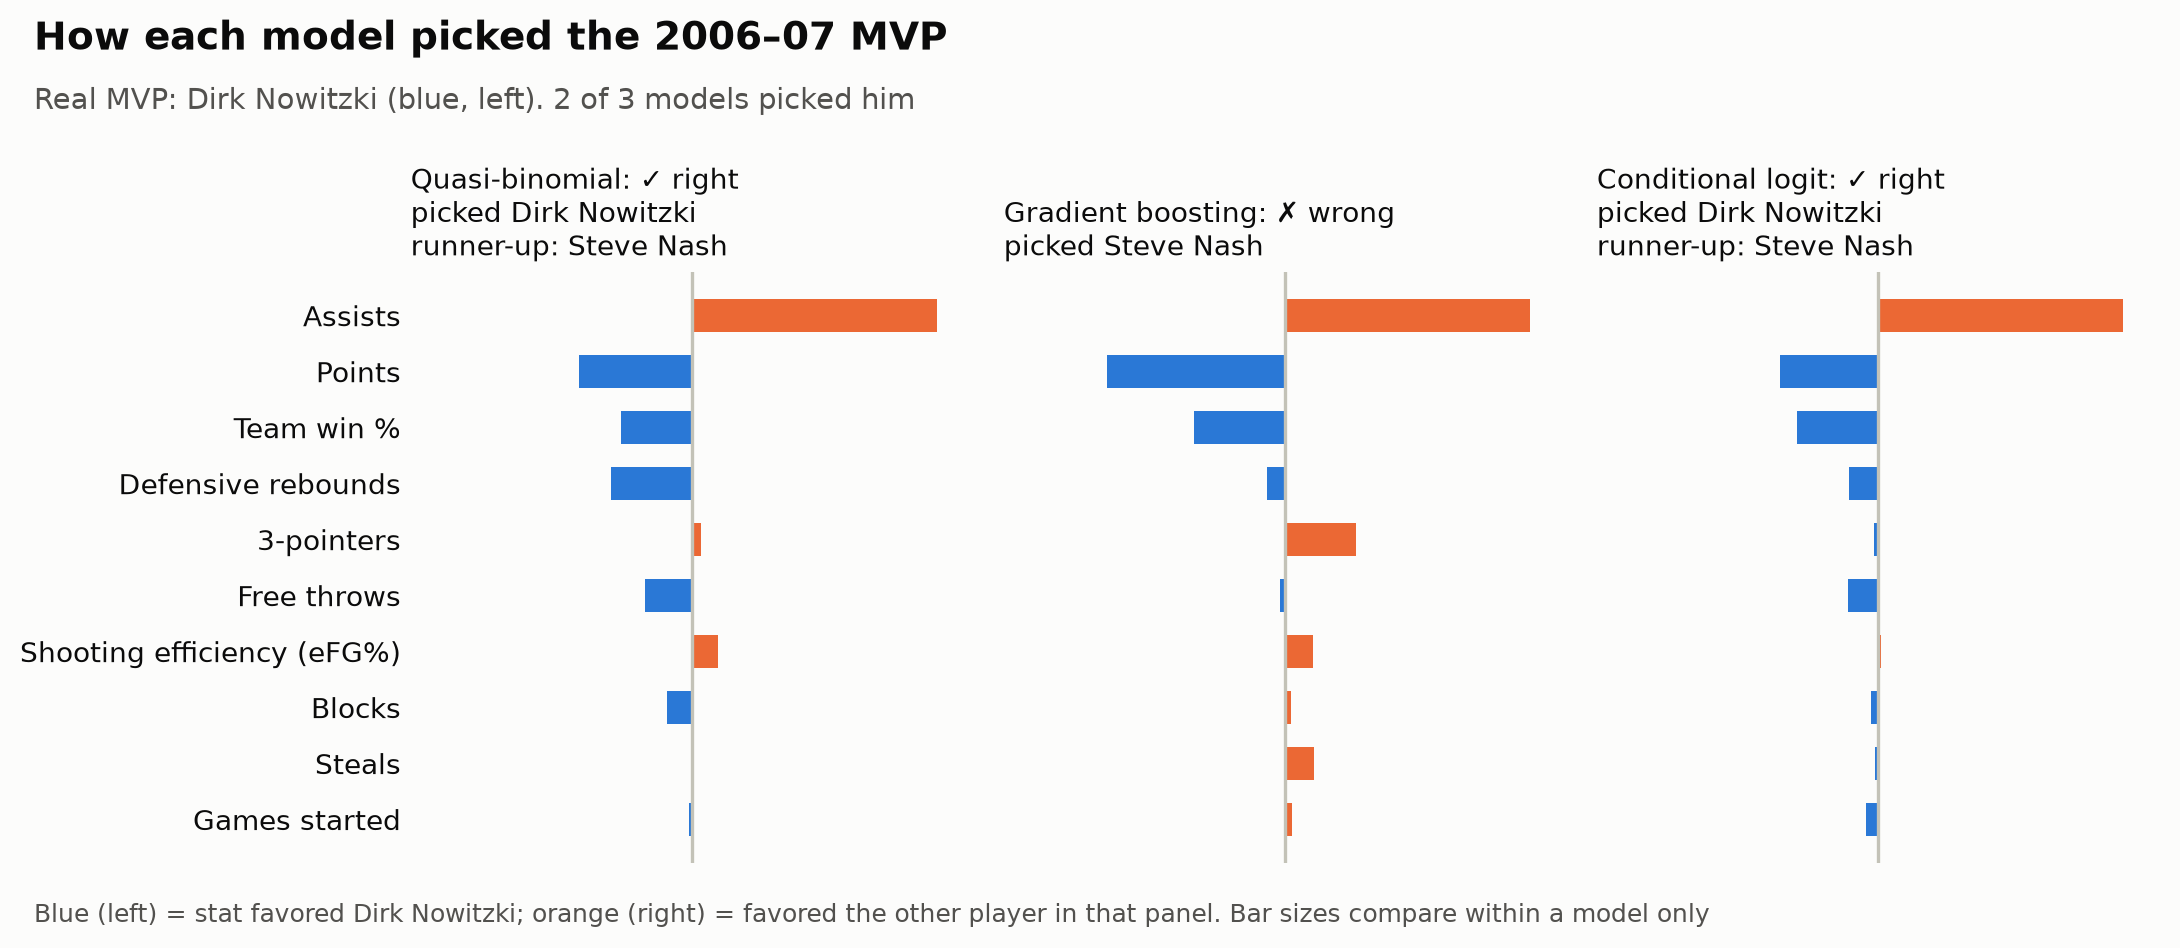

In [51]:
#seasons we could use in the slides as examples: 2016-17 (all three missed), 2014-15 (1 of 3 right), 2006-07 (2 of 3 right, mirrors Nash 2004-05)
for yr in [2016, 2014, 2006]:
    plot_case(yr)

Each panel compares the real MVP (blue bars, left) with one other player (orange bars, right): the model's pick if it was wrong, or its runner-up if it was right. If blue outweighs orange, the model picked the real MVP. Bar sizes only compare within a model.
- **2016–17:** team win % (Rockets, Warriors) pulled every model away from Westbrook, outweighing his points and rebounds.
- **2014–15:** win % favored Curry in all three models. Only the conditional logit weighted it heavily enough to pick him; the others went with Harden's points and free throws.
- **2006–07:** the linear models picked Dirk over Nash on points and win %. Gradient boosting went with Nash's assists and 3-pointers, the year voters chose Dirk.

## Experiments
1. **MVP streaks:** replace MVP_recency with three yes/no columns: won MVP last season, the last 2 seasons in a row, the last 3 in a row.
2. **Rolling window:** train on only the last 11 (or 20) seasons before each predicted season instead of all earlier seasons, to test whether recent eras predict better.
3. **Nash seasons left out of training:** drop 2004–05 and 2005–06 (the two Nash MVPs) from training only, still scoring every season.

Scored like the main comparison: MVP hits and top 3, each season predicted from earlier seasons only.

In [52]:
#did the player win MVP in each of the last k seasons? k=1: last season, k=2: the last 2 in a row, k=3: the last 3 in a row
#(winners = every (season, player) MVP pair, from the MVP_recency cell)
STREAK = ['won_last1', 'won_last2', 'won_last3']
for k in (1, 2, 3):
    data[f'won_last{k}'] = [int(all((y - j, c) in winners for j in range(1, k + 1)))
                            for y, c in zip(data['Year'], data['Code'])]

print(data[STREAK].sum().to_dict())      #how many player-seasons have each flag
data.loc[data['won_last2'] == 1, ['Year', 'Player'] + STREAK + ['MVPVS', 'MVP']]

{'won_last1': 34, 'won_last2': 10, 'won_last3': 1}


,Year,Player,won_last1,won_last2,won_last3,MVPVS,MVP
443,1983,Moses Malone,1,1,0,0.046,0
716,1985,Larry Bird,1,1,0,0.981,1
863,1986,Larry Bird,1,1,1,0.347,0
1466,1990,Magic Johnson,1,1,0,0.518,0
1789,1992,Michael Jordan,1,1,0,0.577,0
3571,2003,Tim Duncan,1,1,0,0.582,0
4062,2006,Steve Nash,1,1,0,0.785,0
4758,2010,LeBron James,1,1,0,0.431,0
5278,2013,LeBron James,1,1,0,0.713,0
5788,2016,Stephen Curry,1,1,0,0.051,0


In [53]:
def forward_three(zcols, rawcols, window=None):
    """Forward-chaining for all three models over test_years.
    window=None: train on all earlier seasons; window=k: train only on the k seasons before the predicted one."""
    preds = pd.DataFrame(np.nan, index=data.index, columns=list(short))
    for yr in test_years:
        first = yr - window if window else data['Year'].min()
        train = (data['Year'] >= first) & (data['Year'] < yr)
        test = data['Year'] == yr
        assert data.loc[train, 'Year'].max() < yr
        q = sm.GLM(data.loc[train, 'MVPVS'], sm.add_constant(data.loc[train, zcols]),
                   family=sm.families.Binomial()).fit(scale='X2')
        preds.loc[test, 'Quasi-binomial'] = q.predict(sm.add_constant(data.loc[test, zcols], has_constant='add'))
        gb = HistGradientBoostingRegressor(random_state=12, **BEST_GBR).fit(data.loc[train, rawcols], data.loc[train, 'MVPVS'])
        preds.loc[test, 'Gradient boosting'] = gb.predict(data.loc[test, rawcols])
        c = ConditionalLogit(data.loc[train, 'MVP'], data.loc[train, zcols],
                             groups=data.loc[train, 'Year']).fit(disp=False, skip_hessian=True, maxiter=200)
        preds.loc[test, 'Conditional logit'] = data.loc[test, zcols] @ c.params
    return preds

In [54]:
z10, raw10 = [c + '_z' for c in feature_sets['candidates_10']], feature_sets['candidates_10']
versions = {'all history (current)':          (z10,          raw10,          None),
            'all history + streaks':          (z10 + STREAK, raw10 + STREAK, None),
            'last 11 seasons':                (z10,          raw10,          11),
            'last 11 seasons + streaks':      (z10 + STREAK, raw10 + STREAK, 11),
            'last 20 seasons':                (z10,          raw10,          20),
            'last 20 seasons + streaks':      (z10 + STREAK, raw10 + STREAK, 20)}

rows = []
for label_, (zc, rc, w) in versions.items():
    d = data[['Year', 'Code', 'Player', 'MVP']].join(forward_three(zc, rc, w))
    d = d[d['Year'] >= 2001]                               #same seasons as the main comparison
    for name in short:
        hits, n, top3 = score(d, name)
        rows.append({'version': label_, 'model': name, 'hits': f'{hits}/{n}', 'top3': f'{top3}/{n}'})
pd.DataFrame(rows).pivot(index='version', columns='model', values='hits').loc[list(versions)]

model,Conditional logit,Gradient boosting,Quasi-binomial
version,,,
all history (current),13/18,12/18,11/18
all history + streaks,13/18,12/18,10/18
last 11 seasons,10/18,8/18,10/18
last 11 seasons + streaks,8/18,8/18,10/18
last 20 seasons,9/18,9/18,9/18
last 20 seasons + streaks,12/18,10/18,9/18


In [55]:
#experiment: leave the two Nash MVP seasons (2004-05, 2005-06) out of TRAINING only.
#Every season, Nash's included, is still predicted and scored, so the comparison is fair.
NASH_SEASONS = {2004, 2005}

def forward_hgbr(cols, exclude=()):
    """Forward-chaining HGBR; seasons in `exclude` are never used for training."""
    pred = pd.Series(np.nan, index=data.index)
    for yr in test_years:
        train = (data['Year'] < yr) & ~data['Year'].isin(exclude)
        test = data['Year'] == yr
        model = HistGradientBoostingRegressor(random_state=12, **BEST_GBR)
        model.fit(data.loc[train, cols], data.loc[train, 'MVPVS'])
        pred[test] = model.predict(data.loc[test, cols])
    return pred

rows = []
for fs in ['candidates_10', 'rf_recall_6']:
    for tag, ex in [('all seasons', ()), ('without Nash seasons', NASH_SEASONS)]:
        d = data[['Year', 'Code', 'MVP']].assign(pred=forward_hgbr(feature_sets[fs], ex))
        row = {'features': fs, 'training': tag}
        for start in (1990, 2001):
            hits, n, top3 = score(d[d['Year'] >= start], 'pred')
            row[f'hits {start}-2018'] = f'{hits}/{n}'
            row[f'top3 {start}-2018'] = f'{top3}/{n}'
        rows.append(row)
pd.DataFrame(rows)

,features,training,hits 1990-2018,top3 1990-2018,hits 2001-2018,top3 2001-2018
0,candidates_10,all seasons,23/29,27/29,12/18,16/18
1,candidates_10,without Nash seasons,24/29,27/29,13/18,16/18
2,rf_recall_6,all seasons,23/29,27/29,14/18,16/18
3,rf_recall_6,without Nash seasons,24/29,26/29,15/18,15/18


**Experiment results:** none of the three changes improved the models beyond noise. Streaks: no gain (there are only 10 back-to-back MVP cases and one three-peat since 1980). Rolling windows: worse for every model (HGBR 12 → 8 of 18 with 11 seasons), suggesting the within-season z-scores already handle era differences and the extra history matters more. Leaving out the Nash seasons: +1 season for HGBR, within noise, so those seasons don't distort what the model learns; they're seasons the stats can't explain. We keep the main setup: all earlier seasons, candidates_10, no past-MVP feature.